In [1]:
print("Projeto Integrador UNIVESP")
print("EDA - Acidentes de trânsito")
print("Município: São Paulo")
print("Ano: 2025")

Projeto Integrador UNIVESP
EDA - Acidentes de trânsito
Município: São Paulo
Ano: 2025


In [2]:
import pandas as pd

print("Pandas carregado com sucesso!")
print("Versão:", pd.__version__)

Pandas carregado com sucesso!
Versão: 3.0.1


In [ ]:
# Carregando os três arquivos CSV do Infosiga

sinistros = pd.read_csv("../data/raw/sinistros_2025-2026.csv", sep=";", low_memory=False)
pessoas = pd.read_csv("../data/raw/pessoas_2025-2026.csv", sep=";", low_memory=False)
veiculos = pd.read_csv("../data/raw/veiculos_2025-2026.csv", sep=";", low_memory=False)

print("Arquivos carregados com sucesso!")
print("Sinistros:", sinistros.shape)
print("Pessoas:", pessoas.shape)
print("Veículos:", veiculos.shape)

In [4]:
# Carregando os três arquivos CSV do Infosiga

sinistros = pd.read_csv(
    "sinistros_2025-2026.csv",
    sep=";",
    encoding="latin1",
    low_memory=False
)

pessoas = pd.read_csv(
    "pessoas_2025-2026.csv",
    sep=";",
    encoding="latin1",
    low_memory=False
)

veiculos = pd.read_csv(
    "veiculos_2025-2026.csv",
    sep=";",
    encoding="latin1",
    low_memory=False
)

print("Arquivos carregados com sucesso!")
print("Sinistros:", sinistros.shape)
print("Pessoas:", pessoas.shape)
print("Veículos:", veiculos.shape)

Arquivos carregados com sucesso!
Sinistros: (288089, 50)
Pessoas: (334071, 31)
Veículos: (286688, 12)


In [5]:
print("Municípios encontrados:")
print(sinistros["municipio"].value_counts().head(10))

print("\nAnos encontrados:")
print(sinistros["ano_sinistro"].value_counts().sort_index())

Municípios encontrados:
municipio
SAO PAULO                68142
GUARULHOS                 7685
RIBEIRAO PRETO            7137
CAMPINAS                  7069
SAO JOSE DO RIO PRETO     5006
SAO BERNARDO DO CAMPO     4884
SOROCABA                  4867
SAO JOSE DOS CAMPOS       4465
FRANCA                    3853
SANTO ANDRE               3746
Name: count, dtype: int64

Anos encontrados:
ano_sinistro
2025    190242
2026     97847
Name: count, dtype: int64


In [6]:
# Filtrando somente o município de São Paulo e o ano de 2025

sinistros_sp = sinistros[
    (sinistros["municipio"] == "SAO PAULO") &
    (sinistros["ano_sinistro"] == 2025)
].copy()

pessoas_sp = pessoas[
    (pessoas["municipio"] == "SAO PAULO") &
    (pessoas["ano_sinistro"] == 2025)
].copy()

print("RECORTE DO PROJETO - SÃO PAULO CAPITAL / 2025")
print("----------------------------------------------")
print("Sinistros:", sinistros_sp.shape)
print("Pessoas:", pessoas_sp.shape)

RECORTE DO PROJETO - SÃO PAULO CAPITAL / 2025
----------------------------------------------
Sinistros: (42671, 50)
Pessoas: (57594, 31)


In [7]:
# Selecionando os veículos relacionados aos sinistros
# de São Paulo capital em 2025

ids_sinistros_sp = sinistros_sp["id_sinistro"].unique()

veiculos_sp = veiculos[
    veiculos["id_sinistro"].isin(ids_sinistros_sp)
].copy()

print("BASES DO PROJETO - SÃO PAULO CAPITAL / 2025")
print("--------------------------------------------")
print("Sinistros:", sinistros_sp.shape)
print("Pessoas:", pessoas_sp.shape)
print("Veículos:", veiculos_sp.shape)

BASES DO PROJETO - SÃO PAULO CAPITAL / 2025
--------------------------------------------
Sinistros: (42671, 50)
Pessoas: (57594, 31)
Veículos: (47739, 12)


In [8]:
# Auditoria inicial das três bases

print("AUDITORIA DOS DADOS - SÃO PAULO / 2025")
print("=" * 50)

print("\n1. SINISTROS")
print("Linhas:", len(sinistros_sp))
print("IDs de sinistros únicos:", sinistros_sp["id_sinistro"].nunique())
print("Linhas duplicadas:", sinistros_sp.duplicated().sum())

print("\n2. PESSOAS")
print("Linhas:", len(pessoas_sp))
print("IDs de pessoas únicos:", pessoas_sp["id_pessoa"].nunique())
print("Sinistros representados:", pessoas_sp["id_sinistro"].nunique())
print("Linhas duplicadas:", pessoas_sp.duplicated().sum())

print("\n3. VEÍCULOS")
print("Linhas:", len(veiculos_sp))
print("IDs de veículos únicos:", veiculos_sp["id_veiculo"].nunique())
print("Sinistros representados:", veiculos_sp["id_sinistro"].nunique())
print("Linhas duplicadas:", veiculos_sp.duplicated().sum())

AUDITORIA DOS DADOS - SÃO PAULO / 2025

1. SINISTROS
Linhas: 42671
IDs de sinistros únicos: 42671
Linhas duplicadas: 0

2. PESSOAS
Linhas: 57594
IDs de pessoas únicos: 57594
Sinistros representados: 26664
Linhas duplicadas: 0

3. VEÍCULOS
Linhas: 47739
IDs de veículos únicos: 47739
Sinistros representados: 26379
Linhas duplicadas: 0


In [9]:
# Verificando a relação entre as três bases

ids_s = set(sinistros_sp["id_sinistro"])
ids_p = set(pessoas_sp["id_sinistro"])
ids_v = set(veiculos_sp["id_sinistro"])

print("RELAÇÃO ENTRE AS BASES - SÃO PAULO / 2025")
print("=" * 50)

print("Sinistros na base principal:", len(ids_s))
print("Sinistros com registro de pessoas:", len(ids_p))
print("Sinistros com registro de veículos:", len(ids_v))

print("\nSinistros SEM registro de pessoas:", len(ids_s - ids_p))
print("Sinistros SEM registro de veículos:", len(ids_s - ids_v))

print("\nSinistros presentes nas 3 bases:",
      len(ids_s & ids_p & ids_v))

RELAÇÃO ENTRE AS BASES - SÃO PAULO / 2025
Sinistros na base principal: 42671
Sinistros com registro de pessoas: 26664
Sinistros com registro de veículos: 26379

Sinistros SEM registro de pessoas: 16007
Sinistros SEM registro de veículos: 16292

Sinistros presentes nas 3 bases: 26173


In [10]:
# Verificando valores ausentes na base de sinistros

ausentes_sinistros = sinistros_sp.isnull().sum()

percentual_ausentes = (
    sinistros_sp.isnull().mean() * 100
).round(2)

tabela_ausentes = pd.DataFrame({
    "Quantidade_Ausente": ausentes_sinistros,
    "Percentual_Ausente": percentual_ausentes
})

tabela_ausentes = tabela_ausentes[
    tabela_ausentes["Quantidade_Ausente"] > 0
].sort_values(
    "Percentual_Ausente",
    ascending=False
)

tabela_ausentes

,Quantidade_Ausente,Percentual_Ausente
tp_sinistro_colisao_traseira,42671,100.00
tp_sinistro_atrop_vitima_fora_veic,42662,99.98
tp_sinistro_atrop_animal,42621,99.88
tp_sinistro_colisao_outros,42572,99.77
tp_sinistro_engavetamento,42462,99.51
tp_sinistro_capotamento,42311,99.16
qtd_bicicleta,42092,98.64
qtd_caminhao,41754,97.85
qtd_gravidade_fatal,41656,97.62
qtd_veic_outros,41535,97.34


In [11]:
# Verificando os tipos de registro existentes
# na base de sinistros de São Paulo em 2025

print("TIPOS DE REGISTRO - SÃO PAULO / 2025")
print("=" * 50)

print(sinistros_sp["tipo_registro"].value_counts())

print("\nPercentual:")
print(
    sinistros_sp["tipo_registro"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

TIPOS DE REGISTRO - SÃO PAULO / 2025
tipo_registro
SINISTRO NAO FATAL    25307
NOTIFICACAO           16349
SINISTRO FATAL         1015
Name: count, dtype: int64

Percentual:
tipo_registro
SINISTRO NAO FATAL    59.31
NOTIFICACAO           38.31
SINISTRO FATAL         2.38
Name: proportion, dtype: float64


In [12]:
# Relação entre tipo de registro e presença
# nas bases de pessoas e veículos

analise_relacao = sinistros_sp[
    ["id_sinistro", "tipo_registro"]
].copy()

analise_relacao["tem_pessoa"] = (
    analise_relacao["id_sinistro"].isin(ids_p)
)

analise_relacao["tem_veiculo"] = (
    analise_relacao["id_sinistro"].isin(ids_v)
)

print("TIPO DE REGISTRO X PRESENÇA NA BASE DE PESSOAS")
print("=" * 60)

print(
    pd.crosstab(
        analise_relacao["tipo_registro"],
        analise_relacao["tem_pessoa"]
    )
)

print("\nTIPO DE REGISTRO X PRESENÇA NA BASE DE VEÍCULOS")
print("=" * 60)

print(
    pd.crosstab(
        analise_relacao["tipo_registro"],
        analise_relacao["tem_veiculo"]
    )
)

TIPO DE REGISTRO X PRESENÇA NA BASE DE PESSOAS
tem_pessoa          False  True 
tipo_registro                   
NOTIFICACAO         15802    547
SINISTRO FATAL          0   1015
SINISTRO NAO FATAL    205  25102

TIPO DE REGISTRO X PRESENÇA NA BASE DE VEÍCULOS
tem_veiculo         False  True 
tipo_registro                   
NOTIFICACAO         16291     58
SINISTRO FATAL          1   1014
SINISTRO NAO FATAL      0  25307


In [13]:
# Verificando o tipo primário de sinistro
# para cada categoria de registro

print("TIPO DE REGISTRO X TIPO PRIMÁRIO DO SINISTRO")
print("=" * 70)

tabela_tipo = pd.crosstab(
    sinistros_sp["tipo_registro"],
    sinistros_sp["tp_sinistro_primario"],
    margins=True
)

tabela_tipo

TIPO DE REGISTRO X TIPO PRIMÁRIO DO SINISTRO


tp_sinistro_primario,ATROPELAMENTO,CHOQUE,COLISAO,NAO DISPONIVEL,OUTROS,All
tipo_registro,,,,,,
NOTIFICACAO,2758,55,537,9078,3921,16349
SINISTRO FATAL,407,176,294,0,138,1015
SINISTRO NAO FATAL,3199,951,18140,528,2489,25307
All,6364,1182,18971,9606,6548,42671


In [14]:
# EDA 1 - Distribuição mensal dos registros de sinistros
# São Paulo capital - 2025

sinistros_por_mes = (
    sinistros_sp["mes_sinistro"]
    .value_counts()
    .sort_index()
)

print("REGISTROS DE SINISTROS POR MÊS - 2025")
print("=" * 45)
print(sinistros_por_mes)

print("\nTotal:", sinistros_por_mes.sum())

REGISTROS DE SINISTROS POR MÊS - 2025
mes_sinistro
1     2737
2     3019
3     3275
4     3368
5     3947
6     3755
7     3689
8     3940
9     3645
10    3795
11    3580
12    3921
Name: count, dtype: int64

Total: 42671


In [ ]:
import matplotlib.pyplot as plt

# Nomes dos meses
nomes_meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

# Criando o gráfico
plt.figure(figsize=(12, 6))

plt.bar(
    nomes_meses,
    sinistros_por_mes.values
)

# Título e eixos
plt.title(
    "Registros de Sinistros por Mês - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Mês")
plt.ylabel("Quantidade de registros")

# Colocando o número sobre cada barra
for i, valor in enumerate(sinistros_por_mes.values):
    plt.text(
        i,
        valor + 30,
        str(valor),
        ha="center"
    )

plt.tight_layout()
plt.show()

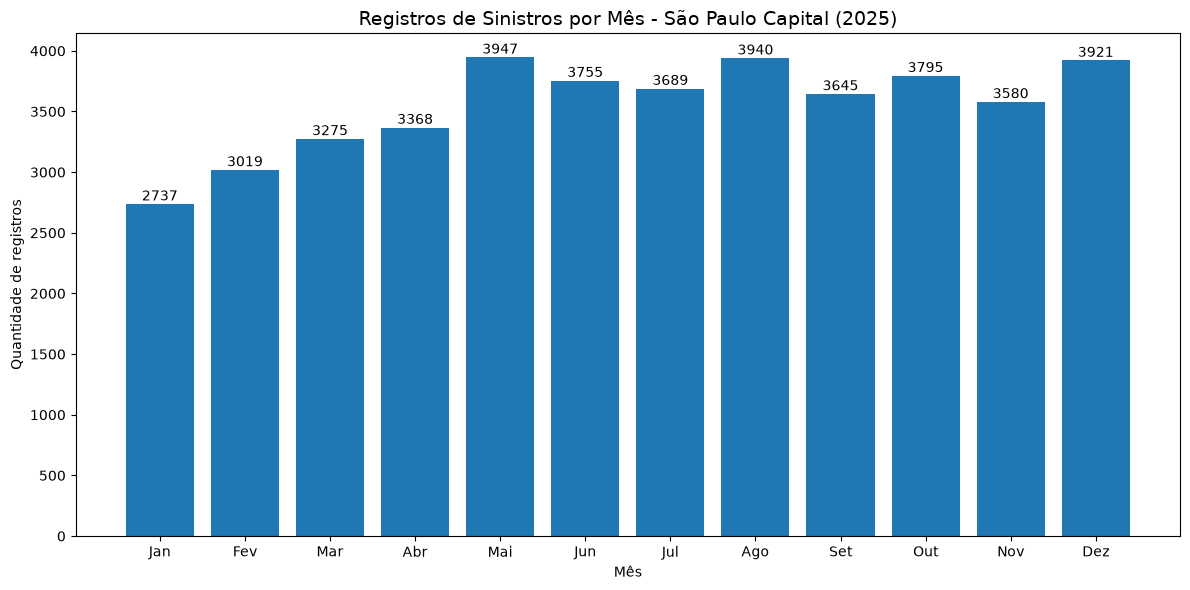

In [19]:
# Primeiro gráfico da EDA
# Registros de sinistros por mês - São Paulo capital / 2025

nomes_meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]

plt.figure(figsize=(12, 6))

plt.bar(
    nomes_meses,
    sinistros_por_mes.values
)

plt.title(
    "Registros de Sinistros por Mês - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Mês")
plt.ylabel("Quantidade de registros")

for i, valor in enumerate(sinistros_por_mes.values):
    plt.text(
        i,
        valor + 30,
        str(valor),
        ha="center"
    )

plt.tight_layout()
plt.savefig("01_sinistros_por_mes_2025.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
# EDA 2 - Distribuição dos registros por dia da semana
# São Paulo capital - 2025

sinistros_por_dia = sinistros_sp["dia_da_semana"].value_counts()

print("REGISTROS DE SINISTROS POR DIA DA SEMANA - 2025")
print("=" * 55)
print(sinistros_por_dia)

print("\nTotal:", sinistros_por_dia.sum())

REGISTROS DE SINISTROS POR DIA DA SEMANA - 2025
dia_da_semana
Sexta-feira      6667
Sábado           6373
Quarta-feira     6131
Quinta-feira     5958
Segunda-feira    5873
Domingo          5861
Terça-feira      5808
Name: count, dtype: int64

Total: 42671


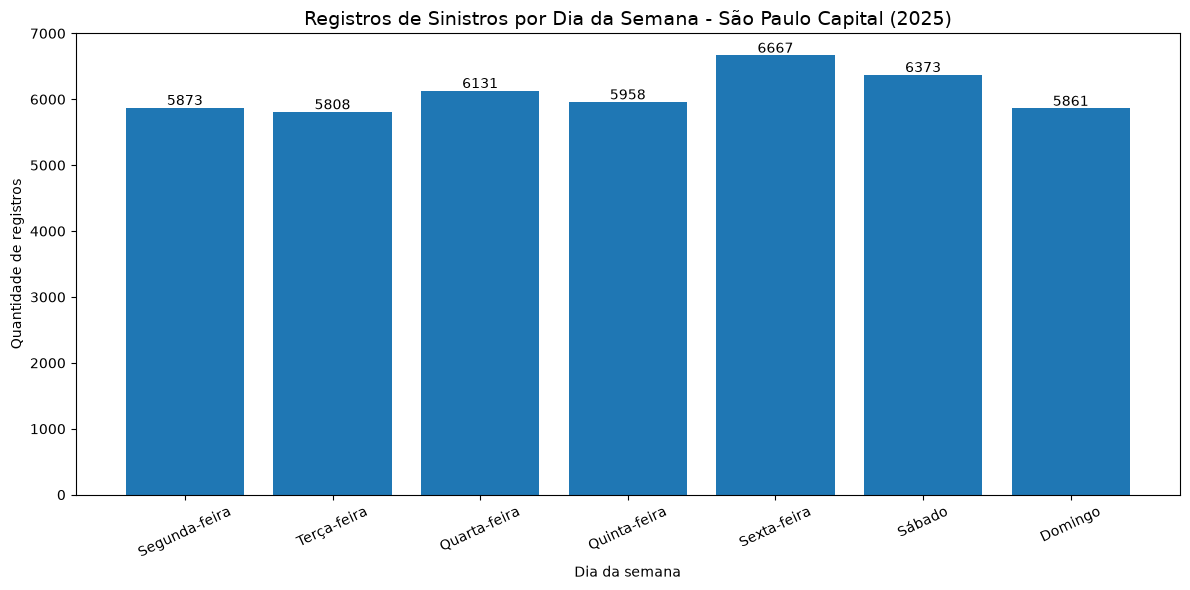

In [21]:
# Gráfico 2 - Registros de sinistros por dia da semana
# São Paulo capital - 2025

ordem_dias = [
    "Segunda-feira",
    "Terça-feira",
    "Quarta-feira",
    "Quinta-feira",
    "Sexta-feira",
    "Sábado",
    "Domingo"
]

sinistros_por_dia_ordenado = (
    sinistros_sp["dia_da_semana"]
    .value_counts()
    .reindex(ordem_dias)
)

plt.figure(figsize=(12, 6))

plt.bar(
    sinistros_por_dia_ordenado.index,
    sinistros_por_dia_ordenado.values
)

plt.title(
    "Registros de Sinistros por Dia da Semana - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Dia da semana")
plt.ylabel("Quantidade de registros")

for i, valor in enumerate(sinistros_por_dia_ordenado.values):
    plt.text(
        i,
        valor + 40,
        str(valor),
        ha="center"
    )

plt.xticks(rotation=25)

plt.tight_layout()

plt.savefig(
    "02_sinistros_por_dia_semana_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# EDA 3 - Distribuição dos registros por turno
# São Paulo capital - 2025

sinistros_por_turno = sinistros_sp["turno"].value_counts()

print("REGISTROS DE SINISTROS POR TURNO - 2025")
print("=" * 50)

print(sinistros_por_turno)

print("\nTotal:", sinistros_por_turno.sum())

REGISTROS DE SINISTROS POR TURNO - 2025
turno
TARDE             13857
NOITE             12812
MANHA             11531
MADRUGADA          4455
NAO DISPONIVEL       16
Name: count, dtype: int64

Total: 42671


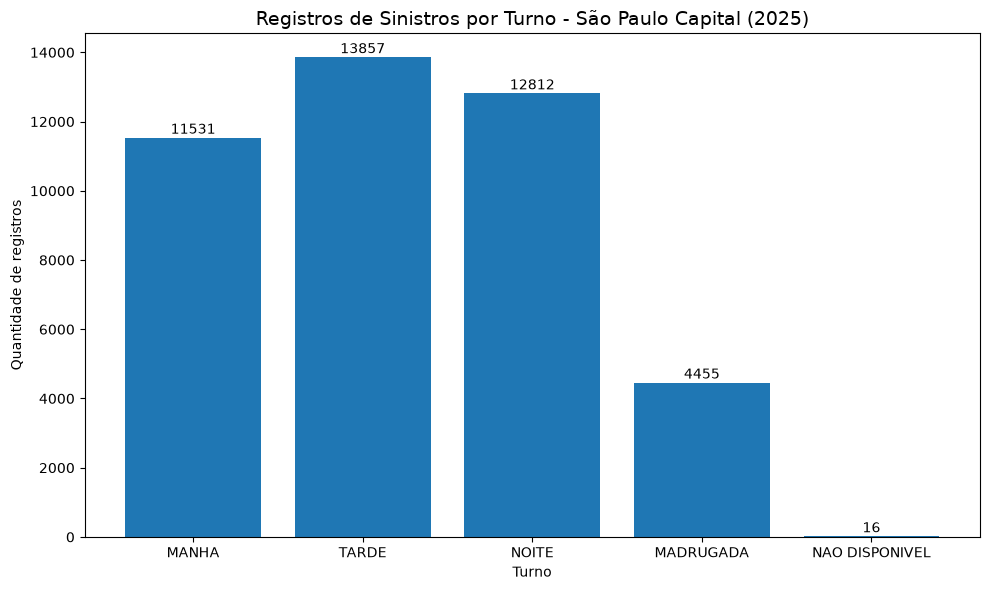

In [23]:
# Gráfico 3 - Registros de sinistros por turno
# São Paulo capital - 2025

ordem_turnos = [
    "MANHA",
    "TARDE",
    "NOITE",
    "MADRUGADA",
    "NAO DISPONIVEL"
]

sinistros_por_turno_ordenado = (
    sinistros_sp["turno"]
    .value_counts()
    .reindex(ordem_turnos)
)

plt.figure(figsize=(10, 6))

plt.bar(
    sinistros_por_turno_ordenado.index,
    sinistros_por_turno_ordenado.values
)

plt.title(
    "Registros de Sinistros por Turno - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Turno")
plt.ylabel("Quantidade de registros")

for i, valor in enumerate(sinistros_por_turno_ordenado.values):
    plt.text(
        i,
        valor + 120,
        str(valor),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "03_sinistros_por_turno_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
# EDA 4 - Verificando o formato da hora do sinistro
# São Paulo capital - 2025

print("FORMATO DA VARIÁVEL HORA DO SINISTRO")
print("=" * 50)

print("Tipo da coluna:")
print(sinistros_sp["hora_sinistro"].dtype)

print("\nPrimeiros 20 valores:")
print(sinistros_sp["hora_sinistro"].head(20))

print("\nQuantidade de valores ausentes:")
print(sinistros_sp["hora_sinistro"].isna().sum())

FORMATO DA VARIÁVEL HORA DO SINISTRO
Tipo da coluna:
str

Primeiros 20 valores:
11     03:11
12     02:40
33     01:15
36     03:08
42     20:40
62     20:49
70     16:00
71     16:40
73     11:04
87     20:58
95     16:44
100    20:58
103    06:29
104    08:48
105    09:38
107    12:07
109    13:39
112    14:41
125    03:22
140    18:51
Name: hora_sinistro, dtype: str

Quantidade de valores ausentes:
16


In [25]:
# EDA 4 - Distribuição dos registros por hora do dia
# São Paulo capital - 2025

# Criando uma nova coluna apenas para análise
sinistros_sp["hora"] = pd.to_datetime(
    sinistros_sp["hora_sinistro"],
    format="%H:%M",
    errors="coerce"
).dt.hour

sinistros_por_hora = (
    sinistros_sp["hora"]
    .value_counts()
    .sort_index()
)

print("REGISTROS DE SINISTROS POR HORA - 2025")
print("=" * 50)
print(sinistros_por_hora)

print("\nTotal com horário válido:", sinistros_por_hora.sum())
print("Horários ausentes/inválidos:", sinistros_sp["hora"].isna().sum())

REGISTROS DE SINISTROS POR HORA - 2025
hora
0.0      997
1.0      745
2.0      613
3.0      527
4.0      606
5.0      967
6.0     1653
7.0     2378
8.0     2131
9.0     1846
10.0    1641
11.0    1882
12.0    2396
13.0    2314
14.0    2286
15.0    2163
16.0    2337
17.0    2361
18.0    2803
19.0    2727
20.0    2218
21.0    2009
22.0    1770
23.0    1285
Name: count, dtype: int64

Total com horário válido: 42655
Horários ausentes/inválidos: 16


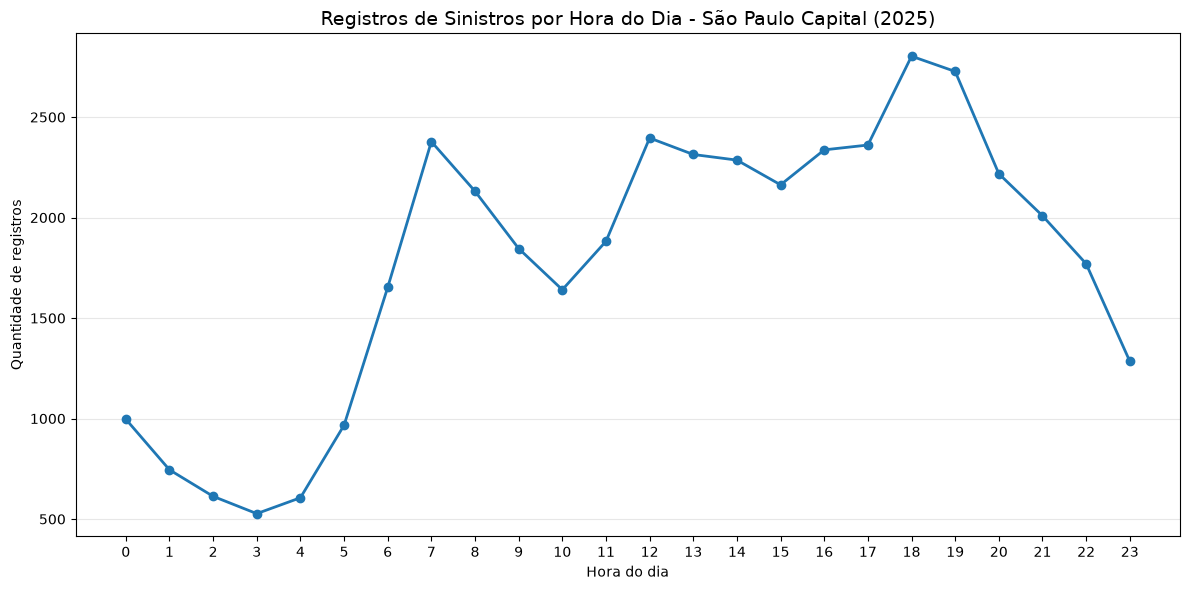

In [26]:
# Gráfico 4 - Registros de sinistros por hora do dia
# São Paulo capital - 2025

horas = range(24)

sinistros_por_hora_ordenado = (
    sinistros_por_hora
    .reindex(horas, fill_value=0)
)

plt.figure(figsize=(12, 6))

plt.plot(
    sinistros_por_hora_ordenado.index,
    sinistros_por_hora_ordenado.values,
    marker="o",
    linewidth=2
)

plt.title(
    "Registros de Sinistros por Hora do Dia - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Hora do dia")
plt.ylabel("Quantidade de registros")

plt.xticks(range(24))

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "04_sinistros_por_hora_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# EDA 5 - Distribuição por tipo primário de sinistro
# São Paulo capital - 2025

tipos_sinistro = sinistros_sp["tp_sinistro_primario"].value_counts()

print("TIPO PRIMÁRIO DOS SINISTROS - SÃO PAULO / 2025")
print("=" * 55)

print(tipos_sinistro)

print("\nPercentual:")
print(
    (sinistros_sp["tp_sinistro_primario"]
     .value_counts(normalize=True) * 100)
    .round(2)
)

print("\nTotal:", tipos_sinistro.sum())

TIPO PRIMÁRIO DOS SINISTROS - SÃO PAULO / 2025
tp_sinistro_primario
COLISAO           18971
NAO DISPONIVEL     9606
OUTROS             6548
ATROPELAMENTO      6364
CHOQUE             1182
Name: count, dtype: int64

Percentual:
tp_sinistro_primario
COLISAO           44.46
NAO DISPONIVEL    22.51
OUTROS            15.35
ATROPELAMENTO     14.91
CHOQUE             2.77
Name: proportion, dtype: float64

Total: 42671


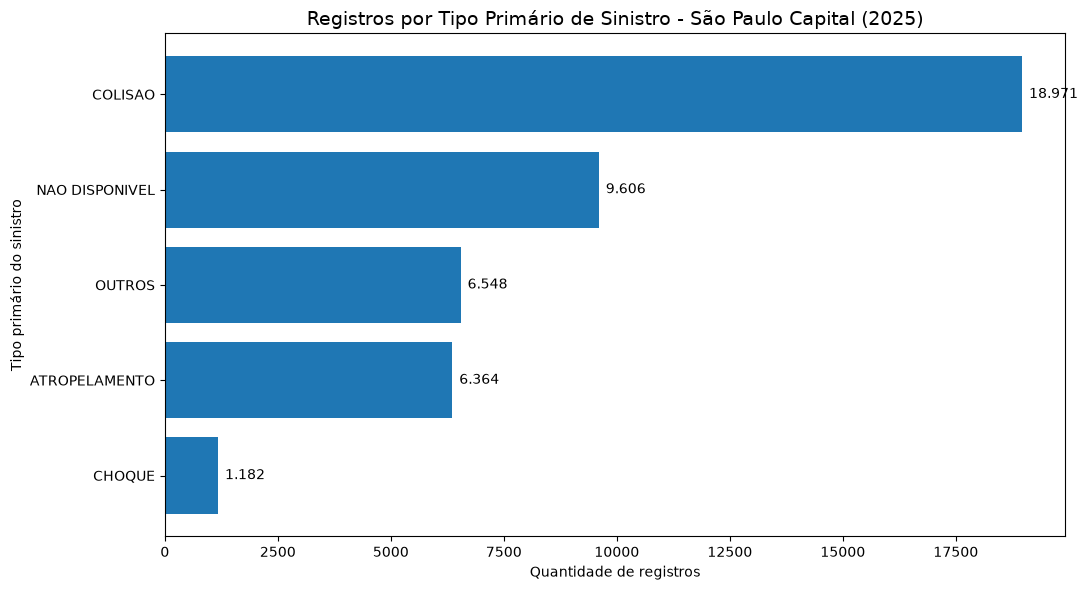

In [28]:
# Gráfico 5 - Distribuição por tipo primário de sinistro
# São Paulo capital - 2025

tipos_sinistro_ordenado = (
    sinistros_sp["tp_sinistro_primario"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(11, 6))

barras = plt.barh(
    tipos_sinistro_ordenado.index,
    tipos_sinistro_ordenado.values
)

plt.title(
    "Registros por Tipo Primário de Sinistro - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Quantidade de registros")
plt.ylabel("Tipo primário do sinistro")

for barra in barras:
    valor = int(barra.get_width())

    plt.text(
        valor + 150,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:,}".replace(",", "."),
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "05_tipo_primario_sinistro_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
# EDA 6 - Gravidade das lesões das pessoas
# São Paulo capital - 2025

gravidade_pessoas = pessoas_sp["gravidade_lesao"].value_counts()

print("GRAVIDADE DAS LESÕES - PESSOAS - SÃO PAULO / 2025")
print("=" * 60)

print(gravidade_pessoas)

print("\nPercentual:")
print(
    (pessoas_sp["gravidade_lesao"]
     .value_counts(normalize=True) * 100)
    .round(2)
)

print("\nTotal de registros de pessoas:", gravidade_pessoas.sum())

print(
    "Valores ausentes:",
    pessoas_sp["gravidade_lesao"].isna().sum()
)

GRAVIDADE DAS LESÕES - PESSOAS - SÃO PAULO / 2025
gravidade_lesao
LEVE              27505
ILESO             25002
GRAVE              2210
NAO DISPONIVEL     1842
FATAL              1035
Name: count, dtype: int64

Percentual:
gravidade_lesao
LEVE              47.76
ILESO             43.41
GRAVE              3.84
NAO DISPONIVEL     3.20
FATAL              1.80
Name: proportion, dtype: float64

Total de registros de pessoas: 57594
Valores ausentes: 0


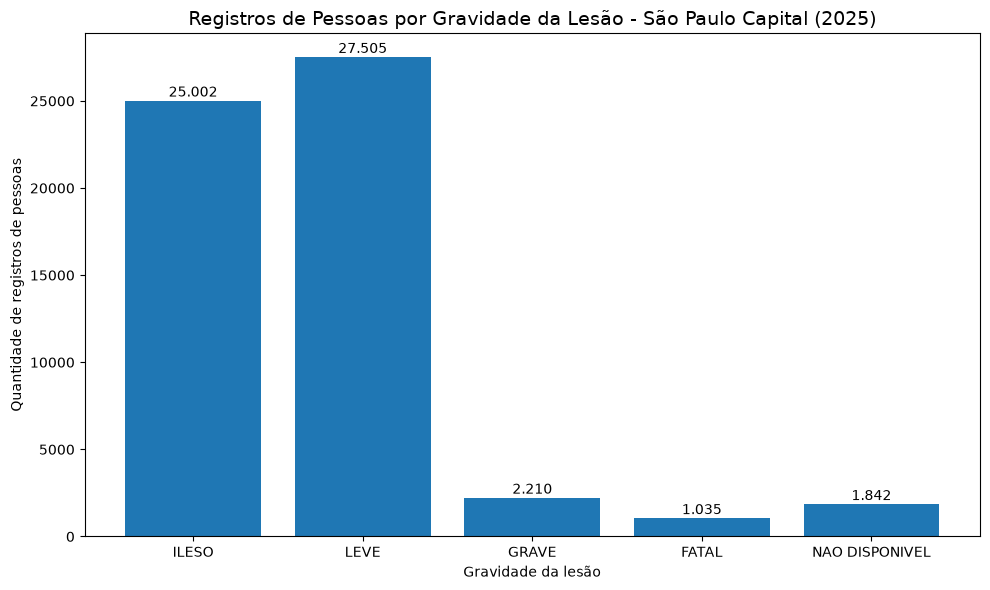

In [30]:
# Gráfico 6 - Gravidade das lesões das pessoas
# São Paulo capital - 2025

ordem_gravidade = [
    "ILESO",
    "LEVE",
    "GRAVE",
    "FATAL",
    "NAO DISPONIVEL"
]

gravidade_ordenada = (
    pessoas_sp["gravidade_lesao"]
    .value_counts()
    .reindex(ordem_gravidade)
)

plt.figure(figsize=(10, 6))

barras = plt.bar(
    gravidade_ordenada.index,
    gravidade_ordenada.values
)

plt.title(
    "Registros de Pessoas por Gravidade da Lesão - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Gravidade da lesão")
plt.ylabel("Quantidade de registros de pessoas")

for barra in barras:
    valor = int(barra.get_height())

    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 250,
        f"{valor:,}".replace(",", "."),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "06_gravidade_lesoes_pessoas_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
# EDA 7 - Verificando os modos de transporte das pessoas
# São Paulo capital - 2025

print("MODOS DE TRANSPORTE DAS PESSOAS - SÃO PAULO / 2025")
print("=" * 60)

print(pessoas_sp["modo_transporte_vitima"].value_counts(dropna=False))

print("\nPercentual:")
print(
    (pessoas_sp["modo_transporte_vitima"]
     .value_counts(dropna=False, normalize=True) * 100)
    .round(2)
)

print("\nTotal de registros:", len(pessoas_sp))

MODOS DE TRANSPORTE DAS PESSOAS - SÃO PAULO / 2025
modo_transporte_vitima
MOTOCICLETA       21977
AUTOMOVEL         20741
NaN                5843
PEDESTRE           4705
ONIBUS             2425
OUTROS              931
CAMINHAO            926
BICICLETA            35
NAO DISPONIVEL       11
Name: count, dtype: int64

Percentual:
modo_transporte_vitima
MOTOCICLETA       38.16
AUTOMOVEL         36.01
NaN               10.15
PEDESTRE           8.17
ONIBUS             4.21
OUTROS             1.62
CAMINHAO           1.61
BICICLETA          0.06
NAO DISPONIVEL     0.02
Name: proportion, dtype: float64

Total de registros: 57594


In [32]:
# EDA 7 - Cruzamento entre modo de transporte e gravidade
# São Paulo capital - 2025

# Criando uma cópia apenas para esta análise
pessoas_transporte = pessoas_sp.copy()

# Identificando os valores ausentes
pessoas_transporte["modo_transporte_vitima"] = (
    pessoas_transporte["modo_transporte_vitima"]
    .fillna("SEM INFORMACAO")
)

tabela_transporte_gravidade = pd.crosstab(
    pessoas_transporte["modo_transporte_vitima"],
    pessoas_transporte["gravidade_lesao"],
    margins=True
)

print("MODO DE TRANSPORTE X GRAVIDADE DA LESÃO")
print("=" * 60)

display(tabela_transporte_gravidade)

MODO DE TRANSPORTE X GRAVIDADE DA LESÃO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL,All
modo_transporte_vitima,,,,,,
AUTOMOVEL,88,240,15943,4462,8,20741
BICICLETA,35,0,0,0,0,35
CAMINHAO,10,10,743,162,1,926
MOTOCICLETA,476,1441,2570,17487,3,21977
NAO DISPONIVEL,11,0,0,0,0,11
ONIBUS,6,5,1898,516,0,2425
OUTROS,1,3,779,143,5,931
PEDESTRE,408,334,752,2862,349,4705
SEM INFORMACAO,0,177,2317,1873,1476,5843


In [33]:
# EDA 7 - Percentual de gravidade dentro de cada modo de transporte
# São Paulo capital - 2025

percentual_transporte_gravidade = pd.crosstab(
    pessoas_transporte["modo_transporte_vitima"],
    pessoas_transporte["gravidade_lesao"],
    normalize="index"
) * 100

# Organizando as colunas
ordem_gravidade = [
    "ILESO",
    "LEVE",
    "GRAVE",
    "FATAL",
    "NAO DISPONIVEL"
]

percentual_transporte_gravidade = (
    percentual_transporte_gravidade
    .reindex(columns=ordem_gravidade)
    .round(2)
)

print("PERCENTUAL DE GRAVIDADE DENTRO DE CADA MODO DE TRANSPORTE")
print("=" * 70)

display(percentual_transporte_gravidade)

PERCENTUAL DE GRAVIDADE DENTRO DE CADA MODO DE TRANSPORTE


gravidade_lesao,ILESO,LEVE,GRAVE,FATAL,NAO DISPONIVEL
modo_transporte_vitima,,,,,
AUTOMOVEL,76.87,21.51,1.16,0.42,0.04
BICICLETA,0.00,0.00,0.00,100.00,0.00
CAMINHAO,80.24,17.49,1.08,1.08,0.11
MOTOCICLETA,11.69,79.57,6.56,2.17,0.01
NAO DISPONIVEL,0.00,0.00,0.00,100.00,0.00
ONIBUS,78.27,21.28,0.21,0.25,0.00
OUTROS,83.67,15.36,0.32,0.11,0.54
PEDESTRE,15.98,60.83,7.10,8.67,7.42
SEM INFORMACAO,39.65,32.06,3.03,0.00,25.26


In [34]:
# EDA 7 - Proporção de registros graves + fatais
# por modo de transporte - São Paulo capital / 2025

resumo_gravidade_transporte = pd.DataFrame({
    "Total_registros":
        pessoas_transporte["modo_transporte_vitima"].value_counts(),

    "Grave_percentual":
        percentual_transporte_gravidade["GRAVE"],

    "Fatal_percentual":
        percentual_transporte_gravidade["FATAL"]
})

resumo_gravidade_transporte["Grave_ou_Fatal_percentual"] = (
    resumo_gravidade_transporte["Grave_percentual"] +
    resumo_gravidade_transporte["Fatal_percentual"]
).round(2)

resumo_gravidade_transporte = (
    resumo_gravidade_transporte
    .sort_values(
        "Grave_ou_Fatal_percentual",
        ascending=False
    )
)

print("GRAVIDADE POR MODO DE TRANSPORTE - SÃO PAULO / 2025")
print("=" * 65)

display(resumo_gravidade_transporte)

GRAVIDADE POR MODO DE TRANSPORTE - SÃO PAULO / 2025


,Total_registros,Grave_percentual,Fatal_percentual,Grave_ou_Fatal_percentual
modo_transporte_vitima,,,,
BICICLETA,35,0.00,100.00,100.00
NAO DISPONIVEL,11,0.00,100.00,100.00
PEDESTRE,4705,7.10,8.67,15.77
MOTOCICLETA,21977,6.56,2.17,8.73
SEM INFORMACAO,5843,3.03,0.00,3.03
CAMINHAO,926,1.08,1.08,2.16
AUTOMOVEL,20741,1.16,0.42,1.58
ONIBUS,2425,0.21,0.25,0.46
OUTROS,931,0.32,0.11,0.43


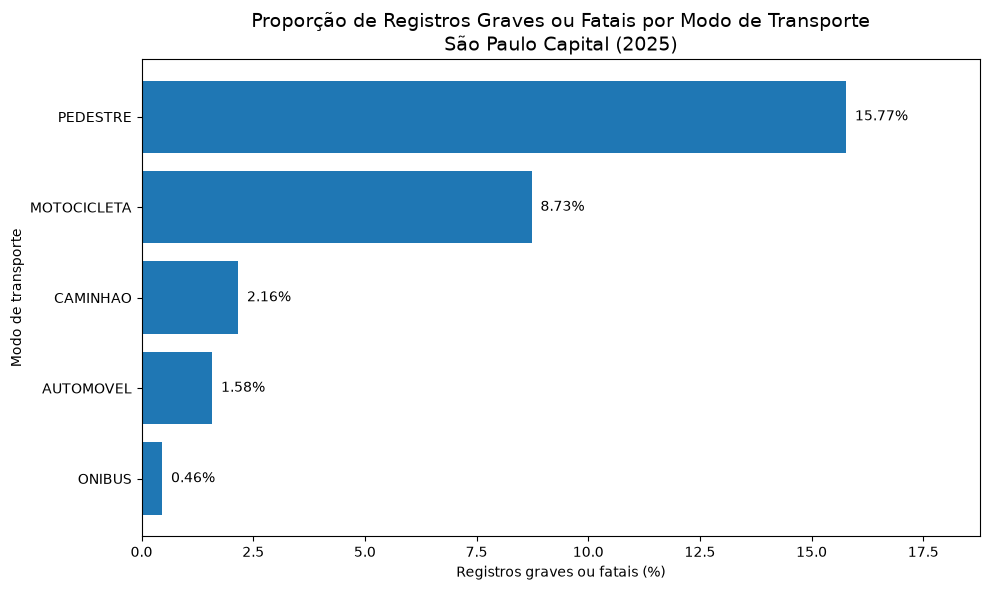

In [35]:
# Gráfico 7 - Percentual de registros graves ou fatais
# por modo de transporte - São Paulo capital / 2025

categorias_grafico = [
    "PEDESTRE",
    "MOTOCICLETA",
    "CAMINHAO",
    "AUTOMOVEL",
    "ONIBUS"
]

dados_grafico = (
    resumo_gravidade_transporte
    .loc[categorias_grafico]
    .sort_values(
        "Grave_ou_Fatal_percentual",
        ascending=True
    )
)

plt.figure(figsize=(10, 6))

barras = plt.barh(
    dados_grafico.index,
    dados_grafico["Grave_ou_Fatal_percentual"]
)

plt.title(
    "Proporção de Registros Graves ou Fatais por Modo de Transporte\n"
    "São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Registros graves ou fatais (%)")
plt.ylabel("Modo de transporte")

for barra in barras:
    valor = barra.get_width()

    plt.text(
        valor + 0.2,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center"
    )

plt.xlim(
    0,
    dados_grafico["Grave_ou_Fatal_percentual"].max() + 3
)

plt.tight_layout()

plt.savefig(
    "07_gravidade_por_modo_transporte_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# EDA 8 - Distribuição das pessoas por faixa etária
# São Paulo capital - 2025

print("FAIXA ETÁRIA DAS PESSOAS - SÃO PAULO / 2025")
print("=" * 60)

faixa_etaria = pessoas_sp["faixa_etaria_demografica"].value_counts(
    dropna=False
)

print(faixa_etaria)

print("\nPercentual:")
print(
    (pessoas_sp["faixa_etaria_demografica"]
     .value_counts(dropna=False, normalize=True) * 100)
    .round(2)
)

print("\nTotal de registros:", len(pessoas_sp))

print(
    "Valores ausentes:",
    pessoas_sp["faixa_etaria_demografica"].isna().sum()
)

FAIXA ETÁRIA DAS PESSOAS - SÃO PAULO / 2025
faixa_etaria_demografica
25 a 29           8683
20 a 24           7708
30 a 34           7110
35 a 39           6809
40 a 44           6419
45 a 49           5243
50 a 54           3937
55 a 59           3028
15 a 19           2377
60 a 64           2141
65 a 69           1447
70 a 74            940
75 a 79            548
10 a 14            392
80 a 84            279
05 a 09            189
85 a 89            135
00 a 04             98
NAO DISPONIVEL      76
90 e +              35
Name: count, dtype: int64

Percentual:
faixa_etaria_demografica
25 a 29           15.08
20 a 24           13.38
30 a 34           12.35
35 a 39           11.82
40 a 44           11.15
45 a 49            9.10
50 a 54            6.84
55 a 59            5.26
15 a 19            4.13
60 a 64            3.72
65 a 69            2.51
70 a 74            1.63
75 a 79            0.95
10 a 14            0.68
80 a 84            0.48
05 a 09            0.33
85 a 89            0.23

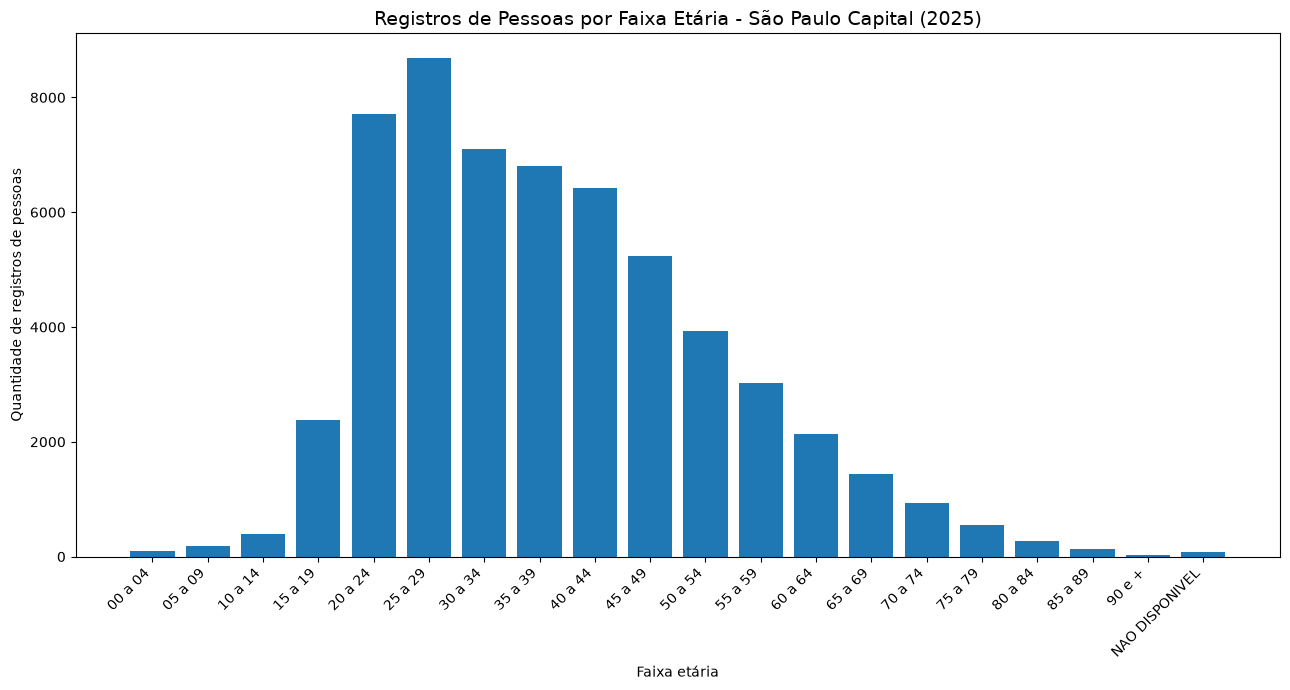

In [37]:
# Gráfico 8 - Registros de pessoas por faixa etária
# São Paulo capital - 2025

ordem_faixas = [
    "00 a 04",
    "05 a 09",
    "10 a 14",
    "15 a 19",
    "20 a 24",
    "25 a 29",
    "30 a 34",
    "35 a 39",
    "40 a 44",
    "45 a 49",
    "50 a 54",
    "55 a 59",
    "60 a 64",
    "65 a 69",
    "70 a 74",
    "75 a 79",
    "80 a 84",
    "85 a 89",
    "90 e +",
    "NAO DISPONIVEL"
]

faixa_etaria_ordenada = (
    pessoas_sp["faixa_etaria_demografica"]
    .value_counts()
    .reindex(ordem_faixas)
)

plt.figure(figsize=(13, 7))

barras = plt.bar(
    faixa_etaria_ordenada.index,
    faixa_etaria_ordenada.values
)

plt.title(
    "Registros de Pessoas por Faixa Etária - São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Faixa etária")
plt.ylabel("Quantidade de registros de pessoas")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "08_pessoas_por_faixa_etaria_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
# Faixa etária x gravidade da lesão
# São Paulo capital - 2025

tabela_idade_gravidade = pd.crosstab(
    pessoas_sp["faixa_etaria_demografica"],
    pessoas_sp["gravidade_lesao"]
)

print("FAIXA ETÁRIA X GRAVIDADE DA LESÃO")
print("=" * 65)

display(tabela_idade_gravidade)

# Calculando os percentuais dentro de cada faixa etária
percentual_idade_gravidade = pd.crosstab(
    pessoas_sp["faixa_etaria_demografica"],
    pessoas_sp["gravidade_lesao"],
    normalize="index"
) * 100

percentual_idade_gravidade = percentual_idade_gravidade.round(2)

print("\nPERCENTUAL DE GRAVIDADE DENTRO DE CADA FAIXA ETÁRIA")
print("=" * 65)

display(percentual_idade_gravidade)

FAIXA ETÁRIA X GRAVIDADE DA LESÃO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
faixa_etaria_demografica,,,,,
00 a 04,3,6,12,52,25
05 a 09,4,13,5,125,42
10 a 14,6,37,10,269,70
15 a 19,73,167,404,1577,156
20 a 24,125,392,1988,4909,294
25 a 29,133,407,2886,4969,288
30 a 34,83,311,2947,3552,217
35 a 39,81,200,3138,3206,184
40 a 44,84,190,3287,2690,168



PERCENTUAL DE GRAVIDADE DENTRO DE CADA FAIXA ETÁRIA


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
faixa_etaria_demografica,,,,,
00 a 04,3.06,6.12,12.24,53.06,25.51
05 a 09,2.12,6.88,2.65,66.14,22.22
10 a 14,1.53,9.44,2.55,68.62,17.86
15 a 19,3.07,7.03,17.00,66.34,6.56
20 a 24,1.62,5.09,25.79,63.69,3.81
25 a 29,1.53,4.69,33.24,57.23,3.32
30 a 34,1.17,4.37,41.45,49.96,3.05
35 a 39,1.19,2.94,46.09,47.08,2.70
40 a 44,1.31,2.96,51.21,41.91,2.62


GRAVES OU FATAIS POR FAIXA ETÁRIA - SÃO PAULO / 2025


,Total_registros,Grave_ou_Fatal
faixa_etaria_demografica,,
00 a 04,98,9.18
05 a 09,189,8.99
10 a 14,392,10.97
15 a 19,2377,10.10
20 a 24,7708,6.71
25 a 29,8683,6.22
30 a 34,7110,5.54
35 a 39,6809,4.13
40 a 44,6419,4.27


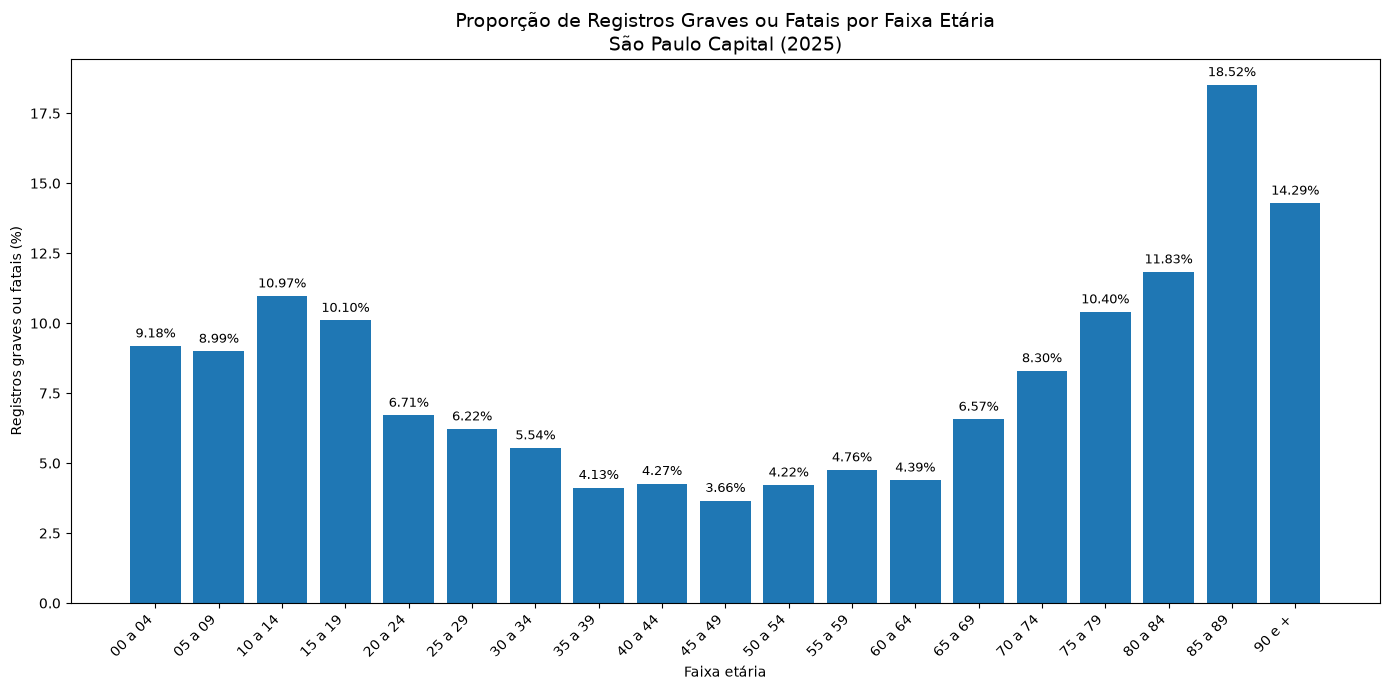

In [39]:
# Gráfico 9 - Proporção de registros graves ou fatais por faixa etária
# São Paulo capital - 2025

# Total de registros por faixa etária
total_idade = pessoas_sp[
    pessoas_sp["faixa_etaria_demografica"] != "NAO DISPONIVEL"
].groupby("faixa_etaria_demografica").size()

# Registros graves ou fatais
grave_fatal_idade = pessoas_sp[
    (pessoas_sp["faixa_etaria_demografica"] != "NAO DISPONIVEL") &
    (pessoas_sp["gravidade_lesao"].isin(["GRAVE", "FATAL"]))
].groupby("faixa_etaria_demografica").size()

# Percentual de grave ou fatal dentro de cada faixa
percentual_grave_fatal_idade = (
    grave_fatal_idade / total_idade * 100
).fillna(0)

# Colocando em ordem etária
ordem_idades = [
    "00 a 04", "05 a 09", "10 a 14", "15 a 19",
    "20 a 24", "25 a 29", "30 a 34", "35 a 39",
    "40 a 44", "45 a 49", "50 a 54", "55 a 59",
    "60 a 64", "65 a 69", "70 a 74", "75 a 79",
    "80 a 84", "85 a 89", "90 e +"
]

percentual_grave_fatal_idade = (
    percentual_grave_fatal_idade
    .reindex(ordem_idades)
    .fillna(0)
)

print("GRAVES OU FATAIS POR FAIXA ETÁRIA - SÃO PAULO / 2025")
print("=" * 65)

resultado_idade = pd.DataFrame({
    "Total_registros": total_idade.reindex(ordem_idades),
    "Grave_ou_Fatal": percentual_grave_fatal_idade
})

resultado_idade["Grave_ou_Fatal"] = (
    resultado_idade["Grave_ou_Fatal"].round(2)
)

display(resultado_idade)

# Gráfico
plt.figure(figsize=(14, 7))

barras = plt.bar(
    percentual_grave_fatal_idade.index,
    percentual_grave_fatal_idade.values
)

plt.title(
    "Proporção de Registros Graves ou Fatais por Faixa Etária\n"
    "São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Faixa etária")
plt.ylabel("Registros graves ou fatais (%)")

plt.xticks(rotation=45, ha="right")

# Valores sobre as barras
for barra, valor in zip(
    barras,
    percentual_grave_fatal_idade.values
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.2,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "09_gravidade_por_faixa_etaria_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
# Distribuição das pessoas por sexo
# São Paulo capital - 2025

print("SEXO DAS PESSOAS - SÃO PAULO / 2025")
print("=" * 55)

sexo_contagem = pessoas_sp["sexo"].value_counts(dropna=False)

print(sexo_contagem)

print("\nPercentual:")

sexo_percentual = (
    pessoas_sp["sexo"]
    .value_counts(dropna=False, normalize=True)
    .mul(100)
    .round(2)
)

print(sexo_percentual)

print("\nTotal de registros:", len(pessoas_sp))
print("Valores ausentes:", pessoas_sp["sexo"].isna().sum())

SEXO DAS PESSOAS - SÃO PAULO / 2025
sexo
MASCULINO         44244
FEMININO          13323
NAO DISPONIVEL       27
Name: count, dtype: int64

Percentual:
sexo
MASCULINO         76.82
FEMININO          23.13
NAO DISPONIVEL     0.05
Name: proportion, dtype: float64

Total de registros: 57594
Valores ausentes: 0


In [41]:
# Sexo x gravidade da lesão
# São Paulo capital - 2025

tabela_sexo_gravidade = pd.crosstab(
    pessoas_sp["sexo"],
    pessoas_sp["gravidade_lesao"]
)

print("SEXO X GRAVIDADE DA LESÃO")
print("=" * 60)

display(tabela_sexo_gravidade)

# Percentual de cada gravidade dentro de cada sexo
percentual_sexo_gravidade = pd.crosstab(
    pessoas_sp["sexo"],
    pessoas_sp["gravidade_lesao"],
    normalize="index"
) * 100

percentual_sexo_gravidade = percentual_sexo_gravidade.round(2)

print("\nPERCENTUAL DE GRAVIDADE DENTRO DE CADA SEXO")
print("=" * 60)

display(percentual_sexo_gravidade)

SEXO X GRAVIDADE DA LESÃO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
sexo,,,,,
FEMININO,181,435,5368,6690,649
MASCULINO,852,1775,19634,20815,1168
NAO DISPONIVEL,2,0,0,0,25



PERCENTUAL DE GRAVIDADE DENTRO DE CADA SEXO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
sexo,,,,,
FEMININO,1.36,3.27,40.29,50.21,4.87
MASCULINO,1.93,4.01,44.38,47.05,2.64
NAO DISPONIVEL,7.41,0.00,0.00,0.00,92.59


GRAVES OU FATAIS POR SEXO - SÃO PAULO / 2025
sexo
FEMININO     4.62
MASCULINO    5.94
dtype: float64


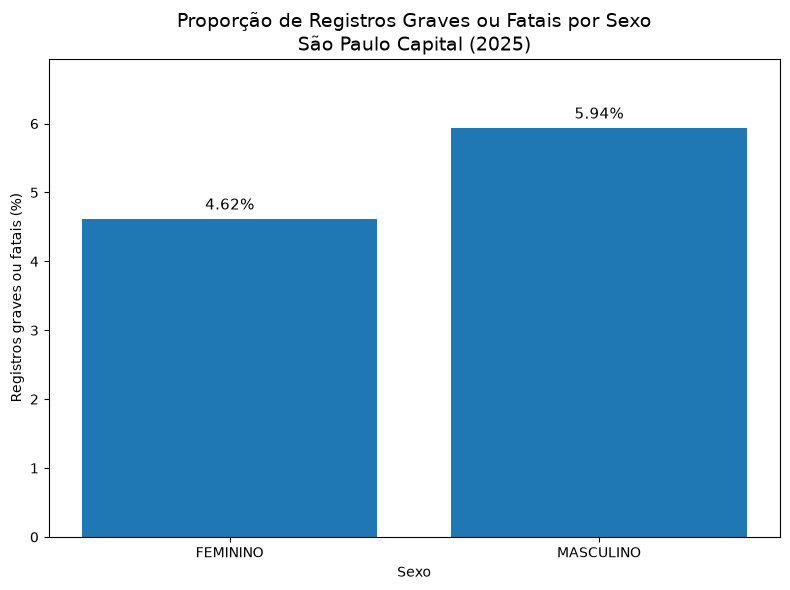

In [42]:
# Gráfico 10 - Proporção de registros graves ou fatais por sexo
# São Paulo capital - 2025

dados_sexo = pessoas_sp[
    pessoas_sp["sexo"].isin(["MASCULINO", "FEMININO"])
].copy()

# Tabela percentual por sexo
tabela_sexo = pd.crosstab(
    dados_sexo["sexo"],
    dados_sexo["gravidade_lesao"],
    normalize="index"
) * 100

# Soma de GRAVE + FATAL
grave_fatal_sexo = (
    tabela_sexo["GRAVE"] +
    tabela_sexo["FATAL"]
).round(2)

# Ordenação
grave_fatal_sexo = grave_fatal_sexo.reindex(
    ["FEMININO", "MASCULINO"]
)

print("GRAVES OU FATAIS POR SEXO - SÃO PAULO / 2025")
print("=" * 55)
print(grave_fatal_sexo)

# Gráfico
plt.figure(figsize=(8, 6))

barras = plt.bar(
    grave_fatal_sexo.index,
    grave_fatal_sexo.values
)

plt.title(
    "Proporção de Registros Graves ou Fatais por Sexo\n"
    "São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Sexo")
plt.ylabel("Registros graves ou fatais (%)")

# Valores sobre as barras
for barra, valor in zip(barras, grave_fatal_sexo.values):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.08,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.ylim(0, max(grave_fatal_sexo.values) + 1)

plt.tight_layout()

plt.savefig(
    "10_gravidade_por_sexo_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
# Distribuição por tipo de vítima
# São Paulo capital - 2025

print("TIPO DE VÍTIMA - SÃO PAULO / 2025")
print("=" * 55)

tipo_vitima_contagem = (
    pessoas_sp["tipo_de_vitima"]
    .value_counts(dropna=False)
)

print(tipo_vitima_contagem)

print("\nPercentual:")

tipo_vitima_percentual = (
    pessoas_sp["tipo_de_vitima"]
    .value_counts(dropna=False, normalize=True)
    .mul(100)
    .round(2)
)

print(tipo_vitima_percentual)

print("\nTotal de registros:", len(pessoas_sp))
print(
    "Valores ausentes:",
    pessoas_sp["tipo_de_vitima"].isna().sum()
)

TIPO DE VÍTIMA - SÃO PAULO / 2025
tipo_de_vitima
PASSAGEIRO        24574
CONDUTOR          24064
PEDESTRE           4705
NAO DISPONIVEL     4251
Name: count, dtype: int64

Percentual:
tipo_de_vitima
PASSAGEIRO        42.67
CONDUTOR          41.78
PEDESTRE           8.17
NAO DISPONIVEL     7.38
Name: proportion, dtype: float64

Total de registros: 57594
Valores ausentes: 0


In [44]:
# Tipo de vítima x gravidade da lesão
# São Paulo capital - 2025

tabela_vitima_gravidade = pd.crosstab(
    pessoas_sp["tipo_de_vitima"],
    pessoas_sp["gravidade_lesao"]
)

print("TIPO DE VÍTIMA X GRAVIDADE DA LESÃO")
print("=" * 65)

display(tabela_vitima_gravidade)

# Percentual dentro de cada tipo de vítima
percentual_vitima_gravidade = pd.crosstab(
    pessoas_sp["tipo_de_vitima"],
    pessoas_sp["gravidade_lesao"],
    normalize="index"
) * 100

percentual_vitima_gravidade = (
    percentual_vitima_gravidade.round(2)
)

print("\nPERCENTUAL DE GRAVIDADE DENTRO DE CADA TIPO DE VÍTIMA")
print("=" * 65)

display(percentual_vitima_gravidade)

TIPO DE VÍTIMA X GRAVIDADE DA LESÃO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
tipo_de_vitima,,,,,
CONDUTOR,520,374,16672,6498,0
NAO DISPONIVEL,36,21,2350,351,1493
PASSAGEIRO,71,1481,5228,17794,0
PEDESTRE,408,334,752,2862,349



PERCENTUAL DE GRAVIDADE DENTRO DE CADA TIPO DE VÍTIMA


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
tipo_de_vitima,,,,,
CONDUTOR,2.16,1.55,69.28,27.00,0.00
NAO DISPONIVEL,0.85,0.49,55.28,8.26,35.12
PASSAGEIRO,0.29,6.03,21.27,72.41,0.00
PEDESTRE,8.67,7.10,15.98,60.83,7.42


GRAVES OU FATAIS POR TIPO DE VÍTIMA - SÃO PAULO / 2025
tipo_de_vitima
PEDESTRE      15.77
PASSAGEIRO     6.32
CONDUTOR       3.72
dtype: float64


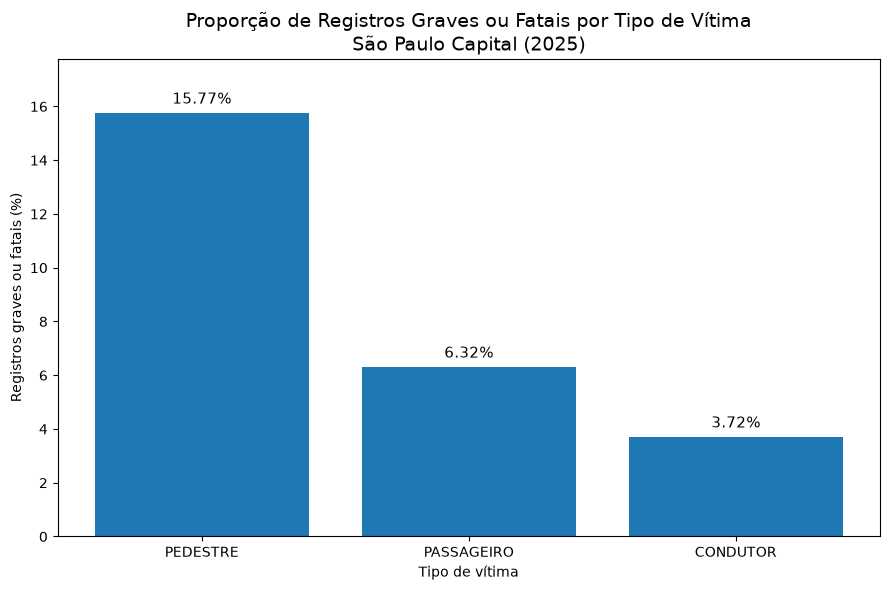

In [45]:
# Gráfico 11 - Proporção de registros graves ou fatais por tipo de vítima
# São Paulo capital - 2025

dados_vitima = pessoas_sp[
    pessoas_sp["tipo_de_vitima"].isin(
        ["CONDUTOR", "PASSAGEIRO", "PEDESTRE"]
    )
].copy()

# Percentual de gravidade dentro de cada tipo de vítima
tabela_vitima = pd.crosstab(
    dados_vitima["tipo_de_vitima"],
    dados_vitima["gravidade_lesao"],
    normalize="index"
) * 100

# Soma de GRAVE + FATAL
grave_fatal_vitima = (
    tabela_vitima["GRAVE"] +
    tabela_vitima["FATAL"]
).round(2)

# Ordenar do maior para o menor
grave_fatal_vitima = grave_fatal_vitima.sort_values(
    ascending=False
)

print("GRAVES OU FATAIS POR TIPO DE VÍTIMA - SÃO PAULO / 2025")
print("=" * 65)
print(grave_fatal_vitima)

# Gráfico
plt.figure(figsize=(9, 6))

barras = plt.bar(
    grave_fatal_vitima.index,
    grave_fatal_vitima.values
)

plt.title(
    "Proporção de Registros Graves ou Fatais por Tipo de Vítima\n"
    "São Paulo Capital (2025)",
    fontsize=14
)

plt.xlabel("Tipo de vítima")
plt.ylabel("Registros graves ou fatais (%)")

# Valores sobre as barras
for barra, valor in zip(
    barras,
    grave_fatal_vitima.values
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.2,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.ylim(
    0,
    max(grave_fatal_vitima.values) + 2
)

plt.tight_layout()

plt.savefig(
    "11_gravidade_por_tipo_vitima_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
# Distribuição dos veículos por tipo
# São Paulo capital - 2025

print("TIPOS DE VEÍCULOS - SÃO PAULO / 2025")
print("=" * 55)

tipo_veiculo_contagem = (
    veiculos_sp["tipo_veiculo"]
    .value_counts(dropna=False)
)

print(tipo_veiculo_contagem)

print("\nPercentual:")

tipo_veiculo_percentual = (
    veiculos_sp["tipo_veiculo"]
    .value_counts(dropna=False, normalize=True)
    .mul(100)
    .round(2)
)

print(tipo_veiculo_percentual)

print("\nTotal de registros:", len(veiculos_sp))

print(
    "Valores ausentes:",
    veiculos_sp["tipo_veiculo"].isna().sum()
)

TIPOS DE VEÍCULOS - SÃO PAULO / 2025
tipo_veiculo
AUTOMOVEL         19773
MOTOCICLETA       19709
NAO DISPONIVEL     3381
ONIBUS             2101
OUTROS             1201
CAMINHAO            995
BICICLETA           579
Name: count, dtype: int64

Percentual:
tipo_veiculo
AUTOMOVEL         41.42
MOTOCICLETA       41.28
NAO DISPONIVEL     7.08
ONIBUS             4.40
OUTROS             2.52
CAMINHAO           2.08
BICICLETA          1.21
Name: proportion, dtype: float64

Total de registros: 47739
Valores ausentes: 0


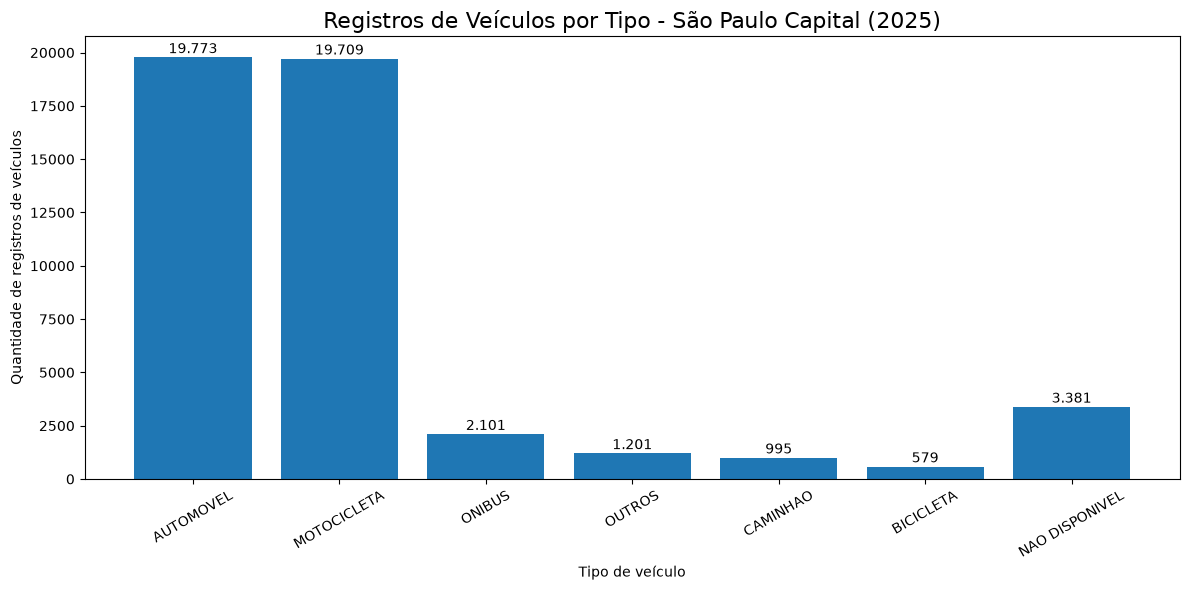

In [47]:
# GRÁFICO 12 - Distribuição dos veículos por tipo
# São Paulo capital - 2025

ordem_veiculos = [
    "AUTOMOVEL",
    "MOTOCICLETA",
    "ONIBUS",
    "OUTROS",
    "CAMINHAO",
    "BICICLETA",
    "NAO DISPONIVEL"
]

dados_veiculos = (
    veiculos_sp["tipo_veiculo"]
    .value_counts()
    .reindex(ordem_veiculos)
)

plt.figure(figsize=(12, 6))

barras = plt.bar(
    dados_veiculos.index,
    dados_veiculos.values
)

plt.title(
    "Registros de Veículos por Tipo - São Paulo Capital (2025)",
    fontsize=16
)

plt.xlabel("Tipo de veículo")
plt.ylabel("Quantidade de registros de veículos")

plt.xticks(rotation=30)

# Valores acima das barras
for barra in barras:
    valor = int(barra.get_height())
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 200,
        f"{valor:,}".replace(",", "."),
        ha="center",
        fontsize=10
    )

plt.tight_layout()

# Salvar para o relatório final
plt.savefig(
    "12_veiculos_por_tipo_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
# Verificando a relação entre veículos e pessoas
# por meio do identificador id_veiculo

print("RELAÇÃO ENTRE AS BASES DE PESSOAS E VEÍCULOS")
print("=" * 60)

# IDs de veículos existentes em cada base
ids_veiculos = set(veiculos_sp["id_veiculo"].dropna())
ids_pessoas_veiculos = set(pessoas_sp["id_veiculo"].dropna())

print("Veículos únicos na base de veículos:",
      veiculos_sp["id_veiculo"].nunique())

print("IDs de veículos presentes na base de pessoas:",
      pessoas_sp["id_veiculo"].nunique())

print("IDs presentes nas duas bases:",
      len(ids_veiculos & ids_pessoas_veiculos))

print("IDs da base de veículos sem correspondência em pessoas:",
      len(ids_veiculos - ids_pessoas_veiculos))

print("IDs informados em pessoas sem correspondência na base de veículos:",
      len(ids_pessoas_veiculos - ids_veiculos))

print("\nPessoas sem id_veiculo:",
      pessoas_sp["id_veiculo"].isna().sum())

RELAÇÃO ENTRE AS BASES DE PESSOAS E VEÍCULOS
Veículos únicos na base de veículos: 47739
IDs de veículos presentes na base de pessoas: 41515
IDs presentes nas duas bases: 41513
IDs da base de veículos sem correspondência em pessoas: 6226
IDs informados em pessoas sem correspondência na base de veículos: 2

Pessoas sem id_veiculo: 10561


In [49]:
# QUANTIDADE DE PESSOAS ASSOCIADAS A CADA VEÍCULO
# São Paulo capital - 2025

pessoas_com_veiculo = pessoas_sp[
    pessoas_sp["id_veiculo"].notna()
].copy()

pessoas_por_veiculo = (
    pessoas_com_veiculo
    .groupby("id_veiculo")
    .size()
)

print("PESSOAS ASSOCIADAS A CADA VEÍCULO")
print("=" * 55)

print("Registros de pessoas com id_veiculo:",
      len(pessoas_com_veiculo))

print("Veículos distintos associados a pessoas:",
      pessoas_por_veiculo.shape[0])

print("\nQuantidade de pessoas por veículo:")
print(pessoas_por_veiculo.value_counts().sort_index())

print("\nMédia de pessoas por veículo:",
      round(pessoas_por_veiculo.mean(), 2))

print("Máximo de pessoas associadas a um veículo:",
      pessoas_por_veiculo.max())

PESSOAS ASSOCIADAS A CADA VEÍCULO
Registros de pessoas com id_veiculo: 47033
Veículos distintos associados a pessoas: 41515

Quantidade de pessoas por veículo:
1     36630
2      4472
3       297
4        72
5        24
6         8
7         3
8         3
9         1
10        2
12        1
13        2
Name: count, dtype: int64

Média de pessoas por veículo: 1.13
Máximo de pessoas associadas a um veículo: 13


In [50]:
# CRUZAMENTO: TIPO DE VEÍCULO X GRAVIDADE DA LESÃO
# São Paulo capital - 2025

# Selecionando somente as informações necessárias da base de veículos
veiculos_tipo = veiculos_sp[
    ["id_veiculo", "tipo_veiculo"]
].drop_duplicates(subset="id_veiculo")

# Associando o tipo do veículo aos registros de pessoas
pessoas_veiculos = pessoas_sp.merge(
    veiculos_tipo,
    on="id_veiculo",
    how="inner"
)

print("CRUZAMENTO PESSOAS X TIPO DE VEÍCULO")
print("=" * 60)

print("Registros resultantes:",
      len(pessoas_veiculos))

print("Pessoas únicas:",
      pessoas_veiculos["id_pessoa"].nunique())

print("Veículos distintos:",
      pessoas_veiculos["id_veiculo"].nunique())

print("\nTIPO DE VEÍCULO X GRAVIDADE DA LESÃO")
print("=" * 60)

tabela_veiculo_gravidade = pd.crosstab(
    pessoas_veiculos["tipo_veiculo"],
    pessoas_veiculos["gravidade_lesao"],
    margins=True
)

display(tabela_veiculo_gravidade)

CRUZAMENTO PESSOAS X TIPO DE VEÍCULO
Registros resultantes: 47031
Pessoas únicas: 47031
Veículos distintos: 41513

TIPO DE VEÍCULO X GRAVIDADE DA LESÃO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL,All
tipo_veiculo,,,,,,
AUTOMOVEL,87,240,15943,4462,8,20740
BICICLETA,35,0,0,0,0,35
CAMINHAO,8,10,743,162,1,924
MOTOCICLETA,474,1441,2570,17487,3,21975
ONIBUS,6,5,1898,516,0,2425
OUTROS,2,3,779,143,5,932
All,612,1699,21933,22770,17,47031


In [51]:
# PROPORÇÃO DE REGISTROS GRAVES OU FATAIS
# POR TIPO DE VEÍCULO
# São Paulo capital - 2025

tabela_pct_veiculo = pd.crosstab(
    pessoas_veiculos["tipo_veiculo"],
    pessoas_veiculos["gravidade_lesao"],
    normalize="index"
) * 100

# Total de registros por tipo
total_tipo_veiculo = (
    pessoas_veiculos["tipo_veiculo"]
    .value_counts()
)

# Criando tabela-resumo
resumo_veiculo_gravidade = pd.DataFrame({
    "Total_registros": total_tipo_veiculo,
    "Grave_percentual": tabela_pct_veiculo.get("GRAVE", 0),
    "Fatal_percentual": tabela_pct_veiculo.get("FATAL", 0)
})

resumo_veiculo_gravidade["Grave_ou_Fatal_percentual"] = (
    resumo_veiculo_gravidade["Grave_percentual"] +
    resumo_veiculo_gravidade["Fatal_percentual"]
)

resumo_veiculo_gravidade = (
    resumo_veiculo_gravidade
    .sort_values(
        "Grave_ou_Fatal_percentual",
        ascending=False
    )
    .round(2)
)

print(
    "GRAVIDADE POR TIPO DE VEÍCULO - "
    "SÃO PAULO / 2025"
)
print("=" * 70)

display(resumo_veiculo_gravidade)

GRAVIDADE POR TIPO DE VEÍCULO - SÃO PAULO / 2025


,Total_registros,Grave_percentual,Fatal_percentual,Grave_ou_Fatal_percentual
tipo_veiculo,,,,
BICICLETA,35,0.00,100.00,100.00
MOTOCICLETA,21975,6.56,2.16,8.71
CAMINHAO,924,1.08,0.87,1.95
AUTOMOVEL,20740,1.16,0.42,1.58
OUTROS,932,0.32,0.21,0.54
ONIBUS,2425,0.21,0.25,0.45


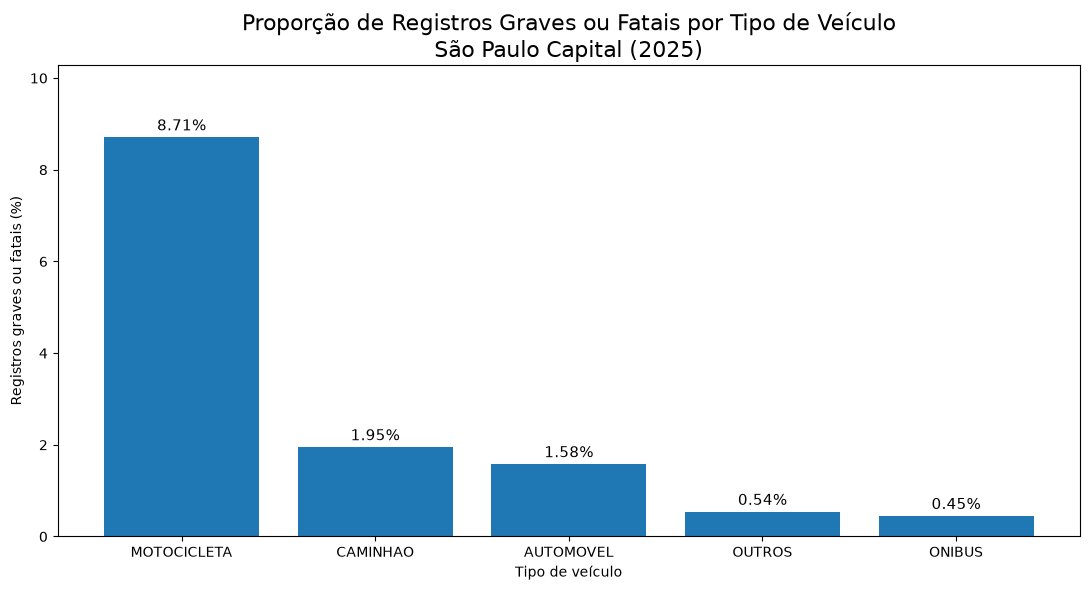

In [52]:
# GRÁFICO 13 - Proporção de registros graves ou fatais
# por tipo de veículo - São Paulo capital / 2025

# Categorias com quantidade suficiente para comparação
tipos_grafico = [
    "MOTOCICLETA",
    "CAMINHAO",
    "AUTOMOVEL",
    "OUTROS",
    "ONIBUS"
]

dados_grafico = (
    resumo_veiculo_gravidade
    .loc[tipos_grafico, "Grave_ou_Fatal_percentual"]
)

plt.figure(figsize=(11, 6))

barras = plt.bar(
    dados_grafico.index,
    dados_grafico.values
)

plt.title(
    "Proporção de Registros Graves ou Fatais por Tipo de Veículo\n"
    "São Paulo Capital (2025)",
    fontsize=16
)

plt.xlabel("Tipo de veículo")
plt.ylabel("Registros graves ou fatais (%)")

# Percentuais acima das barras
for barra, valor in zip(barras, dados_grafico.values):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.15,
        f"{valor:.2f}%",
        ha="center",
        fontsize=11
    )

plt.ylim(0, dados_grafico.max() * 1.18)

plt.tight_layout()

# Salvar para o relatório final
plt.savefig(
    "13_gravidade_por_tipo_veiculo_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [53]:
# AUDITORIA DAS COORDENADAS GEOGRÁFICAS
# São Paulo capital - 2025

print("AUDITORIA ESPACIAL - SÃO PAULO / 2025")
print("=" * 60)

total = len(sinistros_sp)

lat_validas = sinistros_sp["latitude"].notna().sum()
lon_validas = sinistros_sp["longitude"].notna().sum()

coord_validas = (
    sinistros_sp["latitude"].notna() &
    sinistros_sp["longitude"].notna()
).sum()

coord_ausentes = total - coord_validas

print("Total de sinistros:", total)

print("\nLatitude disponível:", lat_validas)
print("Longitude disponível:", lon_validas)

print("\nRegistros com latitude E longitude:",
      coord_validas)

print("Registros sem coordenadas completas:",
      coord_ausentes)

print("\nPercentual com coordenadas completas:",
      round(coord_validas / total * 100, 2), "%")

print("Percentual sem coordenadas completas:",
      round(coord_ausentes / total * 100, 2), "%")

print("\nIntervalo das coordenadas disponíveis:")
print(
    sinistros_sp[
        ["latitude", "longitude"]
    ].describe()
)

AUDITORIA ESPACIAL - SÃO PAULO / 2025
Total de sinistros: 42671

Latitude disponível: 23755
Longitude disponível: 23755

Registros com latitude E longitude: 23755
Registros sem coordenadas completas: 18916

Percentual com coordenadas completas: 55.67 %
Percentual sem coordenadas completas: 44.33 %

Intervalo das coordenadas disponíveis:
        latitude longitude
count      23755     23755
unique     14455     15020
top     -23,5713   -46,701
freq          48        51


In [54]:
# CONVERSÃO DAS COORDENADAS PARA FORMATO NUMÉRICO
# São Paulo capital - 2025

sinistros_sp["latitude_num"] = pd.to_numeric(
    sinistros_sp["latitude"]
        .astype(str)
        .str.replace(",", ".", regex=False),
    errors="coerce"
)

sinistros_sp["longitude_num"] = pd.to_numeric(
    sinistros_sp["longitude"]
        .astype(str)
        .str.replace(",", ".", regex=False),
    errors="coerce"
)

print("VALIDAÇÃO DAS COORDENADAS NUMÉRICAS")
print("=" * 60)

print("Latitude numérica válida:",
      sinistros_sp["latitude_num"].notna().sum())

print("Longitude numérica válida:",
      sinistros_sp["longitude_num"].notna().sum())

print("\nEstatísticas das coordenadas:")
print(
    sinistros_sp[
        ["latitude_num", "longitude_num"]
    ].describe()
)

print("\nMenor e maior latitude:")
print(
    sinistros_sp["latitude_num"].min(),
    sinistros_sp["latitude_num"].max()
)

print("\nMenor e maior longitude:")
print(
    sinistros_sp["longitude_num"].min(),
    sinistros_sp["longitude_num"].max()
)

VALIDAÇÃO DAS COORDENADAS NUMÉRICAS
Latitude numérica válida: 23755
Longitude numérica válida: 23755

Estatísticas das coordenadas:
       latitude_num  longitude_num
count  23755.000000   23755.000000
mean     -23.570314     -46.632768
std        0.094956       0.130923
min      -23.980875     -50.200557
25%      -23.620500     -46.706600
50%      -23.564000     -46.648900
75%      -23.518568     -46.571438
max      -20.249226     -44.708022

Menor e maior latitude:
-23.9808752087 -20.2492255709

Menor e maior longitude:
-50.2005574592 -44.7080221118


In [55]:
# VERIFICAÇÃO PRELIMINAR DE COORDENADAS POTENCIALMENTE ANÔMALAS
# São Paulo capital - 2025

# Registros com coordenadas numéricas
geo_sp = sinistros_sp[
    sinistros_sp["latitude_num"].notna() &
    sinistros_sp["longitude_num"].notna()
].copy()

# Janela ampla de verificação ao redor do município de São Paulo
# Serve apenas para detectar coordenadas claramente distantes.
lat_min, lat_max = -24.0, -23.2
lon_min, lon_max = -47.0, -46.2

geo_sp["coord_janela_sp"] = (
    geo_sp["latitude_num"].between(lat_min, lat_max) &
    geo_sp["longitude_num"].between(lon_min, lon_max)
)

dentro = geo_sp["coord_janela_sp"].sum()
fora = (~geo_sp["coord_janela_sp"]).sum()

print("VERIFICAÇÃO PRELIMINAR DAS COORDENADAS")
print("=" * 60)

print("Total com coordenadas:", len(geo_sp))
print("Dentro da janela de verificação:", dentro)
print("Fora da janela de verificação:", fora)

print(
    "\nPercentual dentro:",
    round(dentro / len(geo_sp) * 100, 2), "%"
)

print(
    "Percentual fora:",
    round(fora / len(geo_sp) * 100, 2), "%"
)

print("\nEXEMPLOS DE REGISTROS FORA DA JANELA:")
display(
    geo_sp.loc[
        ~geo_sp["coord_janela_sp"],
        [
            "id_sinistro",
            "logradouro",
            "latitude_num",
            "longitude_num",
            "tipo_registro",
            "tp_sinistro_primario"
        ]
    ].head(20)
)

VERIFICAÇÃO PRELIMINAR DAS COORDENADAS
Total com coordenadas: 23755
Dentro da janela de verificação: 23637
Fora da janela de verificação: 118

Percentual dentro: 99.5 %
Percentual fora: 0.5 %

EXEMPLOS DE REGISTROS FORA DA JANELA:


,id_sinistro,logradouro,latitude_num,longitude_num,tipo_registro,tp_sinistro_primario
3635,2524888,SP 070,-23.250502,-45.794583,SINISTRO NAO FATAL,COLISAO
4177,2513460,SP 070,-23.348357,-46.046554,NOTIFICACAO,NAO DISPONIVEL
5646,2742192,RAPOSO TAVARES,-23.378643,-48.980362,NOTIFICACAO,OUTROS
5674,2514706,BR 116,-22.544201,-44.785750,SINISTRO NAO FATAL,OUTROS
7338,2526121,BR 116,-22.518264,-44.708022,SINISTRO NAO FATAL,COLISAO
10180,2509174,SP 070,-23.250502,-45.794583,SINISTRO NAO FATAL,CHOQUE
10322,2570401,BR 116,-22.520231,-44.712867,NOTIFICACAO,NAO DISPONIVEL
15846,2533854,SP 330,-20.249226,-47.799046,SINISTRO NAO FATAL,ATROPELAMENTO
19264,2554939,BR 116,-22.520231,-44.712867,NOTIFICACAO,NAO DISPONIVEL
20054,2549396,SP 330,-23.165011,-46.929049,SINISTRO NAO FATAL,COLISAO


In [56]:
# PREPARAÇÃO DA BASE PARA ANÁLISE ESPACIAL
# São Paulo capital - 2025

# Mantém somente coordenadas completas
geo_mapa = sinistros_sp[
    sinistros_sp["latitude_num"].notna() &
    sinistros_sp["longitude_num"].notna()
].copy()

# Recorte espacial preliminar utilizado para o mapa exploratório
geo_mapa = geo_mapa[
    geo_mapa["latitude_num"].between(-24.0, -23.2) &
    geo_mapa["longitude_num"].between(-47.0, -46.2)
].copy()

print("BASE PREPARADA PARA O MAPA")
print("=" * 55)

print("Total de sinistros da pesquisa:",
      len(sinistros_sp))

print("Com coordenadas completas:",
      (
          sinistros_sp["latitude_num"].notna() &
          sinistros_sp["longitude_num"].notna()
      ).sum())

print("Utilizados no mapa exploratório:",
      len(geo_mapa))

print("Sem coordenadas:",
      (
          sinistros_sp["latitude_num"].isna() |
          sinistros_sp["longitude_num"].isna()
      ).sum())

print("Fora da janela espacial preliminar:",
      23755 - len(geo_mapa))

print(
    "\nPercentual da base total representado no mapa:",
    round(len(geo_mapa) / len(sinistros_sp) * 100, 2),
    "%"
)

BASE PREPARADA PARA O MAPA
Total de sinistros da pesquisa: 42671
Com coordenadas completas: 23755
Utilizados no mapa exploratório: 23637
Sem coordenadas: 18916
Fora da janela espacial preliminar: 118

Percentual da base total representado no mapa: 55.39 %


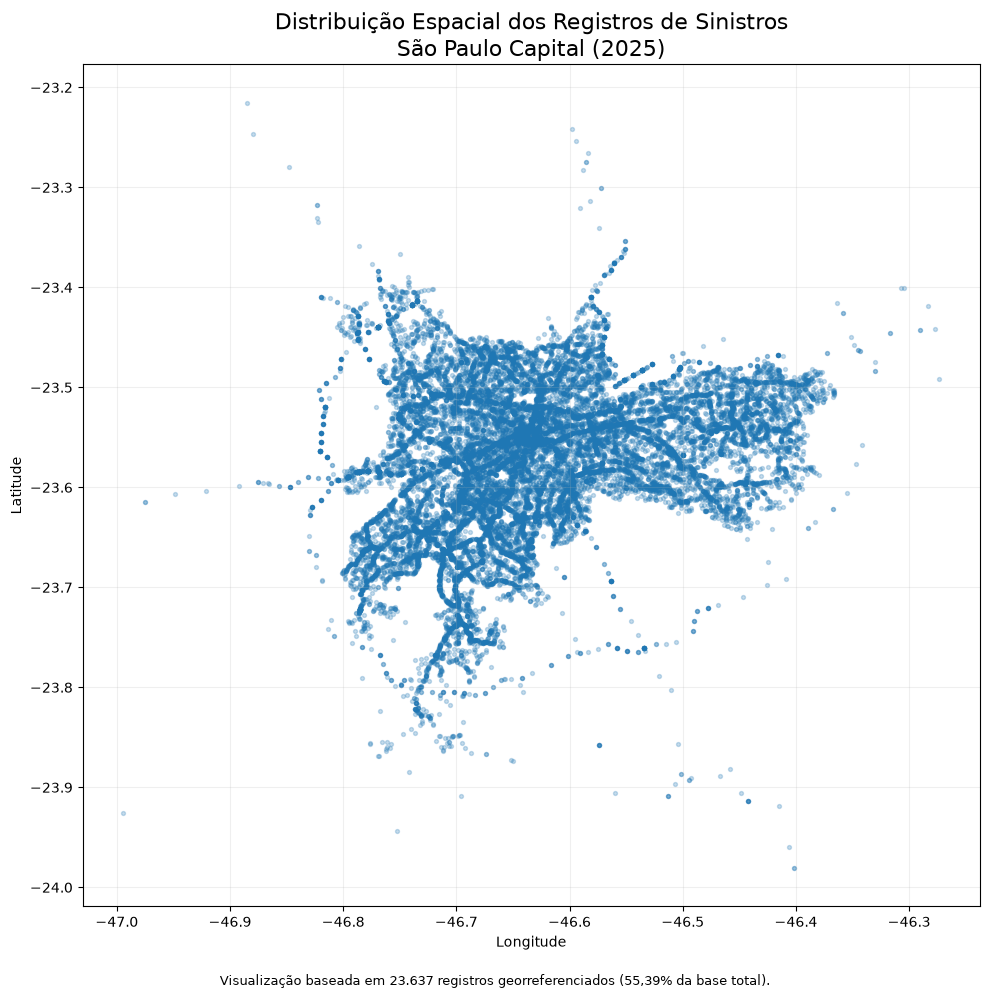

In [57]:
# GRÁFICO 14 - Distribuição espacial dos sinistros
# São Paulo capital - 2025

plt.figure(figsize=(10, 10))

plt.scatter(
    geo_mapa["longitude_num"],
    geo_mapa["latitude_num"],
    s=8,
    alpha=0.25
)

plt.title(
    "Distribuição Espacial dos Registros de Sinistros\n"
    "São Paulo Capital (2025)",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid(
    alpha=0.2
)

# Informação metodológica no próprio gráfico
plt.figtext(
    0.5,
    0.01,
    "Visualização baseada em 23.637 registros georreferenciados "
    "(55,39% da base total).",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.03, 1, 1])

# Salvar para o relatório
plt.savefig(
    "14_distribuicao_espacial_sinistros_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

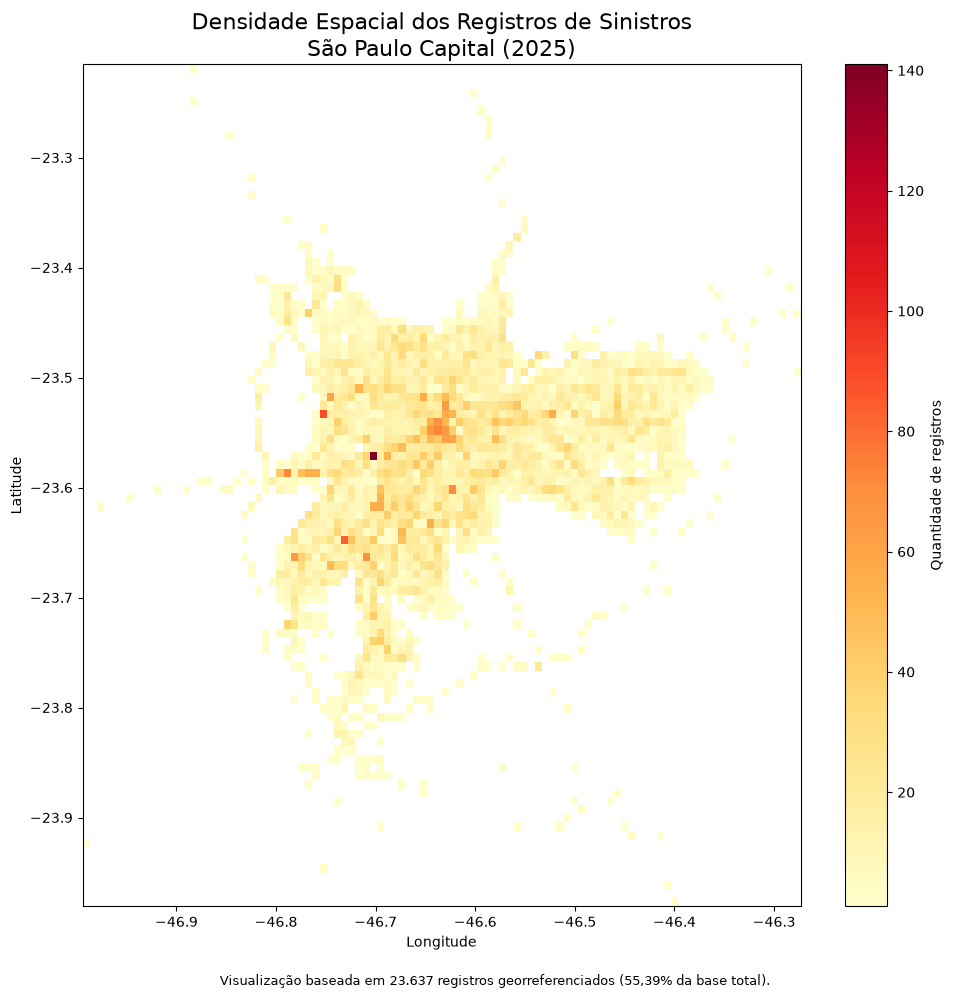

In [58]:
# GRÁFICO 15 - Densidade espacial dos sinistros
# São Paulo capital - 2025

plt.figure(figsize=(10, 10))

# Histograma bidimensional para representar concentração espacial
plt.hist2d(
    geo_mapa["longitude_num"],
    geo_mapa["latitude_num"],
    bins=100,
    cmap="YlOrRd",
    cmin=1
)

# Barra indicando a intensidade
cbar = plt.colorbar()
cbar.set_label("Quantidade de registros")

plt.title(
    "Densidade Espacial dos Registros de Sinistros\n"
    "São Paulo Capital (2025)",
    fontsize=16
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

# Informação metodológica
plt.figtext(
    0.5,
    0.01,
    "Visualização baseada em 23.637 registros georreferenciados "
    "(55,39% da base total).",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.03, 1, 1])

# Salvar para o relatório
plt.savefig(
    "15_densidade_espacial_sinistros_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [59]:
# VERIFICAÇÃO DOS LOGRADOUROS COM MAIS REGISTROS
# São Paulo capital - 2025

top_logradouros = (
    sinistros_sp["logradouro"]
    .value_counts()
    .head(20)
)

print("20 LOGRADOUROS COM MAIOR QUANTIDADE DE REGISTROS")
print("=" * 60)
print(top_logradouros)

print("\nTotal de logradouros diferentes:",
      sinistros_sp["logradouro"].nunique())

print("Registros sem informação de logradouro:",
      sinistros_sp["logradouro"].isna().sum())

20 LOGRADOUROS COM MAIOR QUANTIDADE DE REGISTROS
logradouro
NAO DISPONIVEL                                 1209
SP 015 - PINHEIROS                              640
SP 015 - TIETE                                  411
SP 021                                          372
ESTRADA M BOI MIRIM                             353
AVENIDA ARICANDUVA                              348
AVENIDA SAPOPEMBA                               341
ESTRADA DE ITAPECERICA                          319
AVENIDA SENADOR TEOTONIO VILELA                 310
AVENIDA JACUPESSEGO                             290
SP 270                                          279
AVENIDA DO ESTADO                               277
AVENIDA WASHINGTON LUIS                         250
AVENIDA DONA BELMIRA MARIN                      235
AVENIDA 23 DE MAIO                              225
AVENIDA PROFESSOR LUIZ IGNACIO ANHAIA MELLO     213
AVENIDA RAIMUNDO PEREIRA DE MAGALHAES           209
AVENIDA INTERLAGOS                              204
AVEN

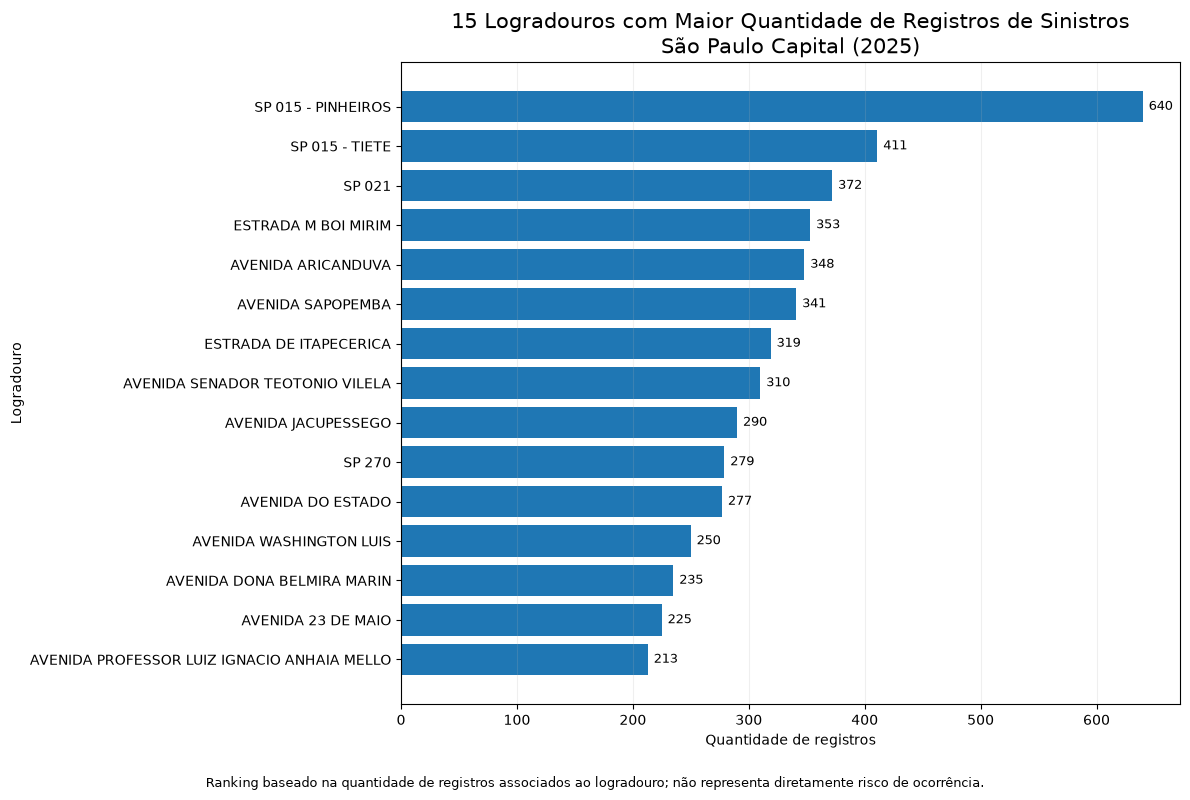

In [60]:
# GRÁFICO 16 - Logradouros com maior quantidade de registros
# São Paulo capital - 2025

# Remover registros sem logradouro útil
logradouros_validos = sinistros_sp[
    sinistros_sp["logradouro"].notna() &
    (sinistros_sp["logradouro"] != "NAO DISPONIVEL")
]

# Selecionar os 15 logradouros com mais registros
top15_logradouros = (
    logradouros_validos["logradouro"]
    .value_counts()
    .head(15)
    .sort_values()
)

# Criar gráfico
plt.figure(figsize=(12, 8))

barras = plt.barh(
    top15_logradouros.index,
    top15_logradouros.values
)

# Colocar quantidade ao lado das barras
for barra in barras:
    valor = int(barra.get_width())

    plt.text(
        barra.get_width() + 5,
        barra.get_y() + barra.get_height()/2,
        f"{valor}",
        va="center",
        fontsize=9
    )

plt.title(
    "15 Logradouros com Maior Quantidade de Registros de Sinistros\n"
    "São Paulo Capital (2025)",
    fontsize=15
)

plt.xlabel("Quantidade de registros")
plt.ylabel("Logradouro")

plt.grid(
    axis="x",
    alpha=0.2
)

plt.figtext(
    0.5,
    0.01,
    "Ranking baseado na quantidade de registros associados ao logradouro; "
    "não representa diretamente risco de ocorrência.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Salvar para o relatório
plt.savefig(
    "16_logradouros_maior_quantidade_sinistros_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [61]:
# LOGRADOUROS COM MAIOR QUANTIDADE DE SINISTROS FATAIS
# São Paulo capital - 2025

fatais_logradouro = sinistros_sp[
    (sinistros_sp["tipo_registro"] == "SINISTRO FATAL") &
    (sinistros_sp["logradouro"].notna()) &
    (sinistros_sp["logradouro"] != "NAO DISPONIVEL")
]

top_fatais_logradouro = (
    fatais_logradouro["logradouro"]
    .value_counts()
    .head(20)
)

print("20 LOGRADOUROS COM MAIOR QUANTIDADE DE REGISTROS DE SINISTROS FATAIS")
print("=" * 70)

print(top_fatais_logradouro)

print("\nTotal de registros de sinistros fatais:",
      len(fatais_logradouro))

print("Logradouros distintos com sinistros fatais:",
      fatais_logradouro["logradouro"].nunique())

20 LOGRADOUROS COM MAIOR QUANTIDADE DE REGISTROS DE SINISTROS FATAIS
logradouro
BR 381                               17
AV. JACU PESSEGO N TRABALHADORES     16
SP 330                               14
SP 015 - TIETE                       13
SP 015 - PINHEIROS                   12
SP 021                                9
AV. SEN TEOTONIO VILELA               9
SP 348                                9
AV. ARICANDUVA                        9
SP 070                                8
AV. ATLANTICA                         8
SP 270                                7
R. DR ASSIS RIBEIRO                   7
AV. DO ESTADO                         7
AV. LUIZ GUSHIKEN                     7
AV. PROF FRANCISCO MORATO             7
ES. M'BOI MIRIM                       6
AV. DAS NACOES UNIDAS                 6
AV. ENG ARMANDO DE ARRUDA PEREIRA     6
AV. RAGUEB CHOHFI                     5
Name: count, dtype: int64

Total de registros de sinistros fatais: 951
Logradouros distintos com sinistros fatais: 615


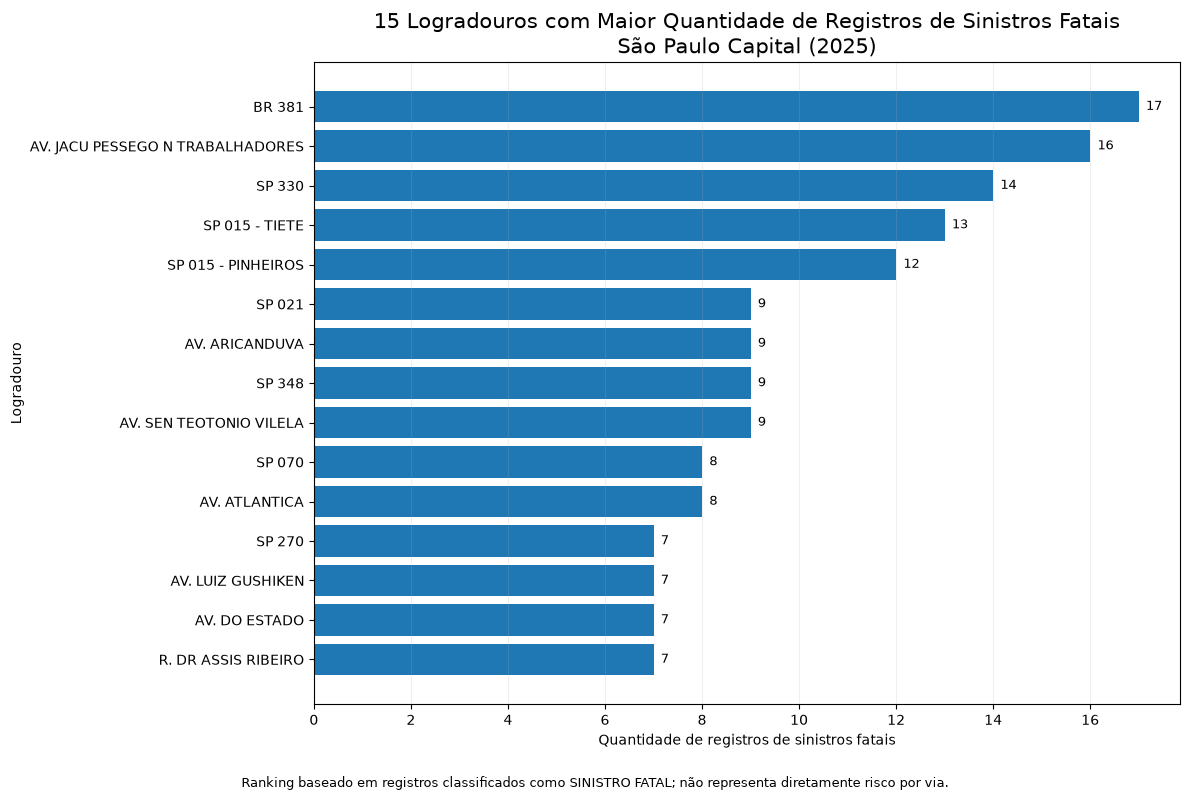

In [62]:
# GRÁFICO 17 - Logradouros com maior quantidade de registros
# classificados como sinistro fatal
# São Paulo capital - 2025

top15_fatais = (
    fatais_logradouro["logradouro"]
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(12, 8))

barras = plt.barh(
    top15_fatais.index,
    top15_fatais.values
)

# Valores nas barras
for barra in barras:
    valor = int(barra.get_width())

    plt.text(
        barra.get_width() + 0.15,
        barra.get_y() + barra.get_height()/2,
        str(valor),
        va="center",
        fontsize=9
    )

plt.title(
    "15 Logradouros com Maior Quantidade de Registros de Sinistros Fatais\n"
    "São Paulo Capital (2025)",
    fontsize=15
)

plt.xlabel("Quantidade de registros de sinistros fatais")
plt.ylabel("Logradouro")

plt.grid(
    axis="x",
    alpha=0.2
)

plt.figtext(
    0.5,
    0.01,
    "Ranking baseado em registros classificados como SINISTRO FATAL; "
    "não representa diretamente risco por via.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    "17_logradouros_sinistros_fatais_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [63]:
# SINISTROS FATAIS POR DIA DA SEMANA
# São Paulo capital - 2025

ordem_dias = [
    "Segunda-feira",
    "Terça-feira",
    "Quarta-feira",
    "Quinta-feira",
    "Sexta-feira",
    "Sábado",
    "Domingo"
]

# Tabela cruzada
dia_tipo = pd.crosstab(
    sinistros_sp["dia_da_semana"],
    sinistros_sp["tipo_registro"]
)

# Organizar os dias
dia_tipo = dia_tipo.reindex(ordem_dias)

print("DIA DA SEMANA X TIPO DE REGISTRO")
print("=" * 60)
display(dia_tipo)

# Percentual de SINISTRO FATAL dentro de cada dia
dia_tipo["Total"] = dia_tipo.sum(axis=1)

dia_tipo["Fatal_percentual"] = (
    dia_tipo["SINISTRO FATAL"] /
    dia_tipo["Total"] * 100
).round(2)

print("\nPERCENTUAL DE REGISTROS FATAIS DENTRO DE CADA DIA")
print("=" * 60)

display(
    dia_tipo[
        ["Total", "SINISTRO FATAL", "Fatal_percentual"]
    ]
)

DIA DA SEMANA X TIPO DE REGISTRO


tipo_registro,NOTIFICACAO,SINISTRO FATAL,SINISTRO NAO FATAL
dia_da_semana,,,
Segunda-feira,2041,127,3705
Terça-feira,2044,104,3660
Quarta-feira,2216,135,3780
Quinta-feira,2161,120,3677
Sexta-feira,2432,171,4064
Sábado,2693,153,3527
Domingo,2762,205,2894



PERCENTUAL DE REGISTROS FATAIS DENTRO DE CADA DIA


tipo_registro,Total,SINISTRO FATAL,Fatal_percentual
dia_da_semana,,,
Segunda-feira,5873,127,2.16
Terça-feira,5808,104,1.79
Quarta-feira,6131,135,2.20
Quinta-feira,5958,120,2.01
Sexta-feira,6667,171,2.56
Sábado,6373,153,2.40
Domingo,5861,205,3.50


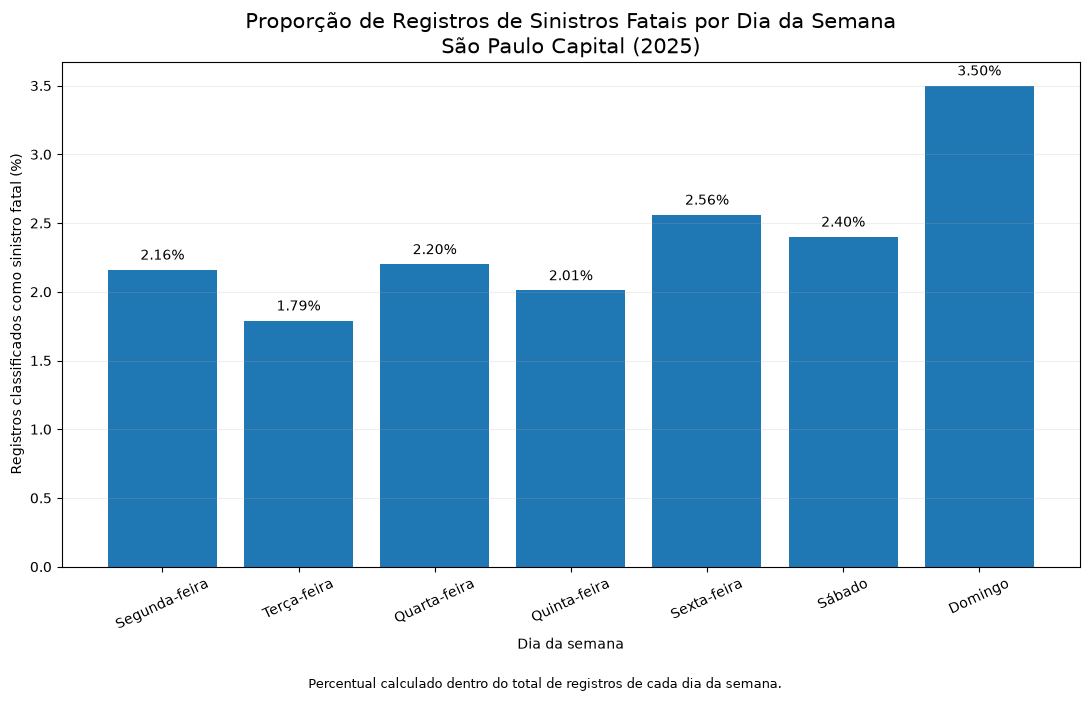

In [64]:
# GRÁFICO 18 - Proporção de registros classificados como
# SINISTRO FATAL por dia da semana
# São Paulo capital - 2025

dados_g18 = dia_tipo["Fatal_percentual"].reindex(ordem_dias)

plt.figure(figsize=(11, 7))

barras = plt.bar(
    dados_g18.index,
    dados_g18.values
)

# Valores percentuais sobre as barras
for barra, valor in zip(barras, dados_g18.values):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 0.05,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title(
    "Proporção de Registros de Sinistros Fatais por Dia da Semana\n"
    "São Paulo Capital (2025)",
    fontsize=15
)

plt.xlabel("Dia da semana")
plt.ylabel("Registros classificados como sinistro fatal (%)")

plt.xticks(rotation=25)

plt.grid(
    axis="y",
    alpha=0.2
)

plt.figtext(
    0.5,
    0.01,
    "Percentual calculado dentro do total de registros de cada dia da semana.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    "18_proporcao_sinistros_fatais_dia_semana_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [65]:
# TURNO X TIPO DE REGISTRO
# São Paulo capital - 2025

ordem_turnos = [
    "MANHA",
    "TARDE",
    "NOITE",
    "MADRUGADA"
]

# Excluir NAO DISPONIVEL para esta comparação
dados_turno = sinistros_sp[
    sinistros_sp["turno"].isin(ordem_turnos)
]

# Tabela cruzada
turno_tipo = pd.crosstab(
    dados_turno["turno"],
    dados_turno["tipo_registro"]
)

# Organizar os turnos
turno_tipo = turno_tipo.reindex(ordem_turnos)

print("TURNO X TIPO DE REGISTRO")
print("=" * 60)

display(turno_tipo)

# Total de registros em cada turno
turno_tipo["Total"] = turno_tipo.sum(axis=1)

# Percentual de registros fatais dentro de cada turno
turno_tipo["Fatal_percentual"] = (
    turno_tipo["SINISTRO FATAL"] /
    turno_tipo["Total"] * 100
).round(2)

print("\nPERCENTUAL DE REGISTROS FATAIS DENTRO DE CADA TURNO")
print("=" * 60)

display(
    turno_tipo[
        ["Total", "SINISTRO FATAL", "Fatal_percentual"]
    ]
)

TURNO X TIPO DE REGISTRO


tipo_registro,NOTIFICACAO,SINISTRO FATAL,SINISTRO NAO FATAL
turno,,,
MANHA,3568,227,7736
TARDE,5316,226,8315
NOITE,5560,307,6945
MADRUGADA,1905,239,2311



PERCENTUAL DE REGISTROS FATAIS DENTRO DE CADA TURNO


tipo_registro,Total,SINISTRO FATAL,Fatal_percentual
turno,,,
MANHA,11531,227,1.97
TARDE,13857,226,1.63
NOITE,12812,307,2.40
MADRUGADA,4455,239,5.36


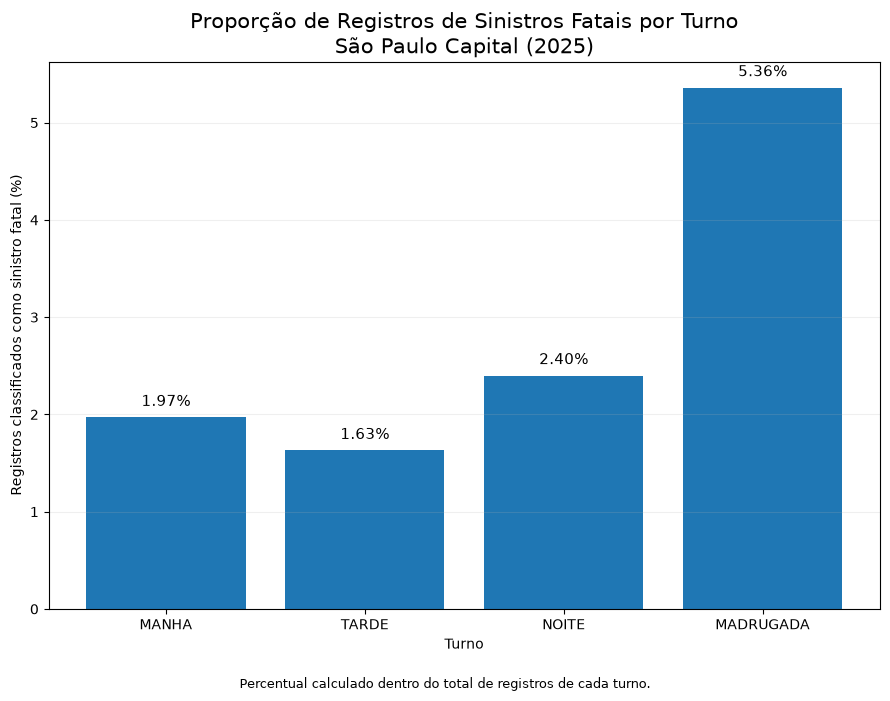

In [66]:
# GRÁFICO 19 - Proporção de registros classificados como
# SINISTRO FATAL por turno
# São Paulo capital - 2025

dados_g19 = turno_tipo["Fatal_percentual"].reindex(ordem_turnos)

plt.figure(figsize=(9, 7))

barras = plt.bar(
    dados_g19.index,
    dados_g19.values
)

# Valores sobre as barras
for barra, valor in zip(barras, dados_g19.values):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 0.08,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title(
    "Proporção de Registros de Sinistros Fatais por Turno\n"
    "São Paulo Capital (2025)",
    fontsize=15
)

plt.xlabel("Turno")
plt.ylabel("Registros classificados como sinistro fatal (%)")

plt.grid(
    axis="y",
    alpha=0.2
)

plt.figtext(
    0.5,
    0.01,
    "Percentual calculado dentro do total de registros de cada turno.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

plt.savefig(
    "19_proporcao_sinistros_fatais_turno_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# DIA DA SEMANA X TURNO X TIPO DE REGISTRO
# São Paulo capital - 2025

ordem_dias = [
    "Segunda-feira",
    "Terça-feira",
    "Quarta-feira",
    "Quinta-feira",
    "Sexta-feira",
    "Sábado",
    "Domingo"
]

ordem_turnos = [
    "MANHA",
    "TARDE",
    "NOITE",
    "MADRUGADA"
]

# Considerar somente os quatro turnos principais
base_dia_turno = sinistros_sp_2025[
    sinistros_sp_2025["turno"].isin(ordem_turnos)
].copy()

# Total de registros por dia e turno
total_dia_turno = pd.crosstab(
    base_dia_turno["dia_da_semana"],
    base_dia_turno["turno"]
)

# Somente registros classificados como SINISTRO FATAL
fatais_dia_turno = pd.crosstab(
    base_dia_turno.loc[
        base_dia_turno["tipo_registro"] == "SINISTRO FATAL",
        "dia_da_semana"
    ],
    base_dia_turno.loc[
        base_dia_turno["tipo_registro"] == "SINISTRO FATAL",
        "turno"
    ]
)

# Organizar linhas e colunas
total_dia_turno = total_dia_turno.reindex(
    index=ordem_dias,
    columns=ordem_turnos,
    fill_value=0
)

fatais_dia_turno = fatais_dia_turno.reindex(
    index=ordem_dias,
    columns=ordem_turnos,
    fill_value=0
)

# Percentual de registros fatais dentro de cada combinação
percentual_fatal_dia_turno = (
    fatais_dia_turno / total_dia_turno * 100
).round(2)

print("TOTAL DE REGISTROS POR DIA E TURNO")
display(total_dia_turno)

print("\nREGISTROS FATAIS POR DIA E TURNO")
display(fatais_dia_turno)

print("\nPERCENTUAL DE REGISTROS FATAIS POR DIA E TURNO")
display(percentual_fatal_dia_turno)

In [ ]:
# Ver as variáveis DataFrame existentes no notebook

for nome, objeto in globals().items():
    if isinstance(objeto, pd.DataFrame):
        print(nome, "->", objeto.shape)

In [69]:
# Listar os DataFrames existentes no notebook
# sem alterar nenhuma variável

for nome, objeto in list(globals().items()):
    if isinstance(objeto, pd.DataFrame):
        print(f"{nome:35} -> {objeto.shape}")

_                                   -> (4, 6)
__                                  -> (33, 2)
sinistros                           -> (288089, 50)
pessoas                             -> (334071, 31)
veiculos                            -> (286688, 12)
sinistros_sp                        -> (42671, 53)
pessoas_sp                          -> (57594, 31)
veiculos_sp                         -> (47739, 12)
tabela_ausentes                     -> (33, 2)
_10                                 -> (33, 2)
analise_relacao                     -> (42671, 4)
tabela_tipo                         -> (4, 6)
_13                                 -> (4, 6)
pessoas_transporte                  -> (57594, 31)
tabela_transporte_gravidade         -> (10, 6)
percentual_transporte_gravidade     -> (9, 5)
resumo_gravidade_transporte         -> (9, 4)
tabela_idade_gravidade              -> (20, 5)
percentual_idade_gravidade          -> (20, 5)
resultado_idade                     -> (19, 2)
tabela_sexo_gravidade          

In [70]:
# DIA DA SEMANA X TURNO X SINISTRO FATAL
# São Paulo capital - 2025

ordem_dias = [
    "Segunda-feira",
    "Terça-feira",
    "Quarta-feira",
    "Quinta-feira",
    "Sexta-feira",
    "Sábado",
    "Domingo"
]

ordem_turnos = [
    "MANHA",
    "TARDE",
    "NOITE",
    "MADRUGADA"
]

# Considerar somente os quatro turnos principais
base_dia_turno = sinistros_sp[
    sinistros_sp["turno"].isin(ordem_turnos)
].copy()

# Total de registros em cada combinação dia x turno
total_dia_turno = pd.crosstab(
    base_dia_turno["dia_da_semana"],
    base_dia_turno["turno"]
)

# Somente registros classificados como SINISTRO FATAL
base_fatais = base_dia_turno[
    base_dia_turno["tipo_registro"] == "SINISTRO FATAL"
]

fatais_dia_turno = pd.crosstab(
    base_fatais["dia_da_semana"],
    base_fatais["turno"]
)

# Colocar dias e turnos na ordem correta
total_dia_turno = total_dia_turno.reindex(
    index=ordem_dias,
    columns=ordem_turnos,
    fill_value=0
)

fatais_dia_turno = fatais_dia_turno.reindex(
    index=ordem_dias,
    columns=ordem_turnos,
    fill_value=0
)

# Percentual de fatais dentro de cada combinação dia x turno
percentual_fatal_dia_turno = (
    fatais_dia_turno
    .div(total_dia_turno)
    .mul(100)
    .round(2)
)

print("TOTAL DE REGISTROS POR DIA E TURNO")
print("=" * 60)
display(total_dia_turno)

print("\nREGISTROS DE SINISTROS FATAIS POR DIA E TURNO")
print("=" * 60)
display(fatais_dia_turno)

print("\nPERCENTUAL DE REGISTROS FATAIS POR DIA E TURNO")
print("=" * 60)
display(percentual_fatal_dia_turno)

TOTAL DE REGISTROS POR DIA E TURNO


turno,MANHA,TARDE,NOITE,MADRUGADA
dia_da_semana,,,,
Segunda-feira,1774,1932,1475,692
Terça-feira,1897,1972,1653,285
Quarta-feira,1874,2125,1738,391
Quinta-feira,1781,1951,1775,449
Sexta-feira,1755,2162,2236,510
Sábado,1366,2118,2004,883
Domingo,1084,1597,1931,1245



REGISTROS DE SINISTROS FATAIS POR DIA E TURNO


turno,MANHA,TARDE,NOITE,MADRUGADA
dia_da_semana,,,,
Segunda-feira,32,29,29,37
Terça-feira,26,30,29,18
Quarta-feira,32,36,40,24
Quinta-feira,34,34,27,23
Sexta-feira,38,40,56,33
Sábado,25,28,59,39
Domingo,40,29,67,65



PERCENTUAL DE REGISTROS FATAIS POR DIA E TURNO


turno,MANHA,TARDE,NOITE,MADRUGADA
dia_da_semana,,,,
Segunda-feira,1.80,1.50,1.97,5.35
Terça-feira,1.37,1.52,1.75,6.32
Quarta-feira,1.71,1.69,2.30,6.14
Quinta-feira,1.91,1.74,1.52,5.12
Sexta-feira,2.17,1.85,2.50,6.47
Sábado,1.83,1.32,2.94,4.42
Domingo,3.69,1.82,3.47,5.22


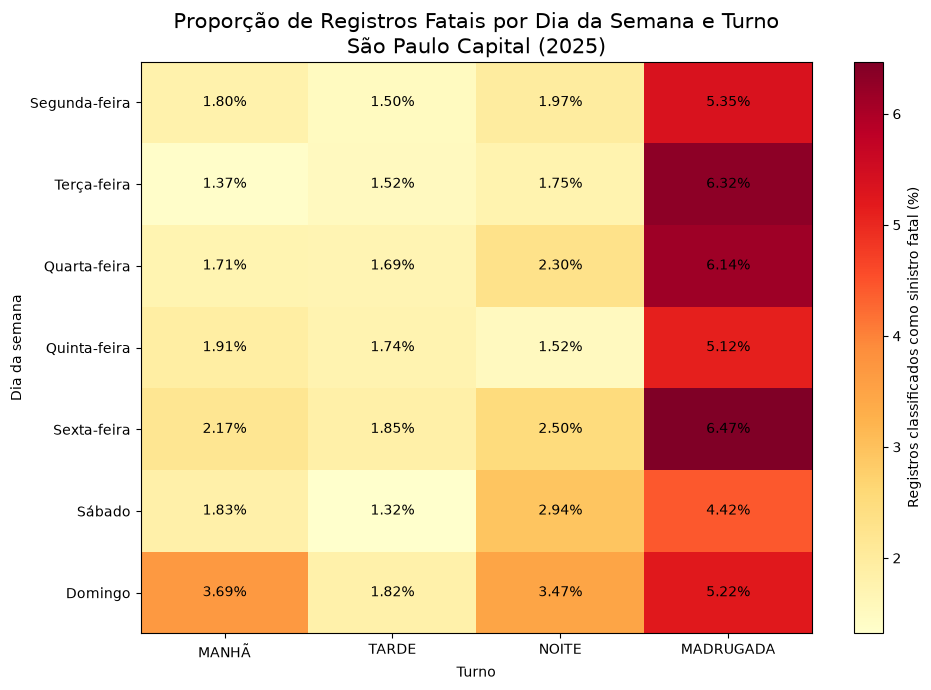

In [71]:
# GRÁFICO 20 - Percentual de registros fatais por dia da semana e turno
# São Paulo capital - 2025

import matplotlib.pyplot as plt
import numpy as np

dados = percentual_fatal_dia_turno.values

fig, ax = plt.subplots(figsize=(10, 7))

imagem = ax.imshow(
    dados,
    aspect="auto",
    cmap="YlOrRd"
)

# Nomes dos turnos
ax.set_xticks(np.arange(len(ordem_turnos)))
ax.set_xticklabels(["MANHÃ", "TARDE", "NOITE", "MADRUGADA"])

# Nomes dos dias
ax.set_yticks(np.arange(len(ordem_dias)))
ax.set_yticklabels(ordem_dias)

# Escrever percentual dentro de cada célula
for i in range(len(ordem_dias)):
    for j in range(len(ordem_turnos)):
        valor = dados[i, j]

        ax.text(
            j,
            i,
            f"{valor:.2f}%",
            ha="center",
            va="center"
        )

# Barra lateral
cbar = plt.colorbar(imagem, ax=ax)
cbar.set_label("Registros classificados como sinistro fatal (%)")

ax.set_title(
    "Proporção de Registros Fatais por Dia da Semana e Turno\n"
    "São Paulo Capital (2025)",
    fontsize=15
)

ax.set_xlabel("Turno")
ax.set_ylabel("Dia da semana")

plt.tight_layout()

# Salvar para o relatório
plt.savefig(
    "20_fatalidade_dia_turno_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [72]:
# AUDITORIA - TIPO DE SINISTRO X GRAVIDADE DA LESÃO
# São Paulo capital - 2025

# Selecionar apenas as informações necessárias da base de sinistros
sinistros_tipo = sinistros_sp[
    ["id_sinistro", "tp_sinistro_primario"]
].copy()

# Verificar se existe mais de uma linha por sinistro
print("AUDITORIA DO CRUZAMENTO")
print("=" * 60)

print("Registros na base de sinistros:", len(sinistros_tipo))
print(
    "IDs de sinistros únicos:",
    sinistros_tipo["id_sinistro"].nunique()
)

print("\nRegistros na base de pessoas:", len(pessoas_sp))
print(
    "IDs de sinistros presentes na base de pessoas:",
    pessoas_sp["id_sinistro"].nunique()
)

# Cruzamento
pessoas_tipo_sinistro = pessoas_sp.merge(
    sinistros_tipo,
    on="id_sinistro",
    how="inner",
    validate="many_to_one"
)

print("\nRESULTADO DO CRUZAMENTO")
print("=" * 60)

print(
    "Registros de pessoas resultantes:",
    len(pessoas_tipo_sinistro)
)

print(
    "Pessoas únicas:",
    pessoas_tipo_sinistro["id_pessoa"].nunique()
)

print(
    "Sinistros distintos representados:",
    pessoas_tipo_sinistro["id_sinistro"].nunique()
)

print(
    "Pessoas da base original sem correspondência:",
    len(pessoas_sp) - len(pessoas_tipo_sinistro)
)

AUDITORIA DO CRUZAMENTO
Registros na base de sinistros: 42671
IDs de sinistros únicos: 42671

Registros na base de pessoas: 57594
IDs de sinistros presentes na base de pessoas: 26664

RESULTADO DO CRUZAMENTO
Registros de pessoas resultantes: 57594
Pessoas únicas: 57594
Sinistros distintos representados: 26664
Pessoas da base original sem correspondência: 0


In [73]:
# TIPO PRIMÁRIO DO SINISTRO X GRAVIDADE DA LESÃO
# São Paulo capital - 2025

# Tabela com quantidades
tabela_tipo_gravidade = pd.crosstab(
    pessoas_tipo_sinistro["tp_sinistro_primario"],
    pessoas_tipo_sinistro["gravidade_lesao"]
)

print("TIPO DE SINISTRO X GRAVIDADE DA LESÃO")
print("=" * 70)

display(tabela_tipo_gravidade)

# Percentual de cada gravidade dentro de cada tipo de sinistro
percentual_tipo_gravidade = pd.crosstab(
    pessoas_tipo_sinistro["tp_sinistro_primario"],
    pessoas_tipo_sinistro["gravidade_lesao"],
    normalize="index"
) * 100

percentual_tipo_gravidade = percentual_tipo_gravidade.round(2)

print("\nPERCENTUAL DE GRAVIDADE DENTRO DE CADA TIPO DE SINISTRO")
print("=" * 70)

display(percentual_tipo_gravidade)

# Criar resumo de graves + fatais
resumo_tipo_gravidade = pd.DataFrame(
    index=percentual_tipo_gravidade.index
)

resumo_tipo_gravidade["Total_registros"] = (
    tabela_tipo_gravidade.sum(axis=1)
)

resumo_tipo_gravidade["Grave_percentual"] = (
    percentual_tipo_gravidade.get("GRAVE", 0)
)

resumo_tipo_gravidade["Fatal_percentual"] = (
    percentual_tipo_gravidade.get("FATAL", 0)
)

resumo_tipo_gravidade["Grave_ou_Fatal_percentual"] = (
    resumo_tipo_gravidade["Grave_percentual"] +
    resumo_tipo_gravidade["Fatal_percentual"]
).round(2)

resumo_tipo_gravidade = resumo_tipo_gravidade.sort_values(
    "Grave_ou_Fatal_percentual",
    ascending=False
)

print("\nGRAVIDADE POR TIPO PRIMÁRIO DE SINISTRO - SÃO PAULO / 2025")
print("=" * 70)

display(resumo_tipo_gravidade)

TIPO DE SINISTRO X GRAVIDADE DA LESÃO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
tp_sinistro_primario,,,,,
ATROPELAMENTO,410,387,3277,3597,420
CHOQUE,185,112,685,1060,131
COLISAO,300,1463,19485,19610,1081
NAO DISPONIVEL,0,39,222,537,0
OUTROS,140,209,1333,2701,210



PERCENTUAL DE GRAVIDADE DENTRO DE CADA TIPO DE SINISTRO


gravidade_lesao,FATAL,GRAVE,ILESO,LEVE,NAO DISPONIVEL
tp_sinistro_primario,,,,,
ATROPELAMENTO,5.07,4.78,40.50,44.46,5.19
CHOQUE,8.51,5.15,31.52,48.78,6.03
COLISAO,0.72,3.49,46.46,46.76,2.58
NAO DISPONIVEL,0.00,4.89,27.82,67.29,0.00
OUTROS,3.05,4.55,29.02,58.81,4.57



GRAVIDADE POR TIPO PRIMÁRIO DE SINISTRO - SÃO PAULO / 2025


,Total_registros,Grave_percentual,Fatal_percentual,Grave_ou_Fatal_percentual
tp_sinistro_primario,,,,
CHOQUE,2173,5.15,8.51,13.66
ATROPELAMENTO,8091,4.78,5.07,9.85
OUTROS,4593,4.55,3.05,7.60
NAO DISPONIVEL,798,4.89,0.00,4.89
COLISAO,41939,3.49,0.72,4.21


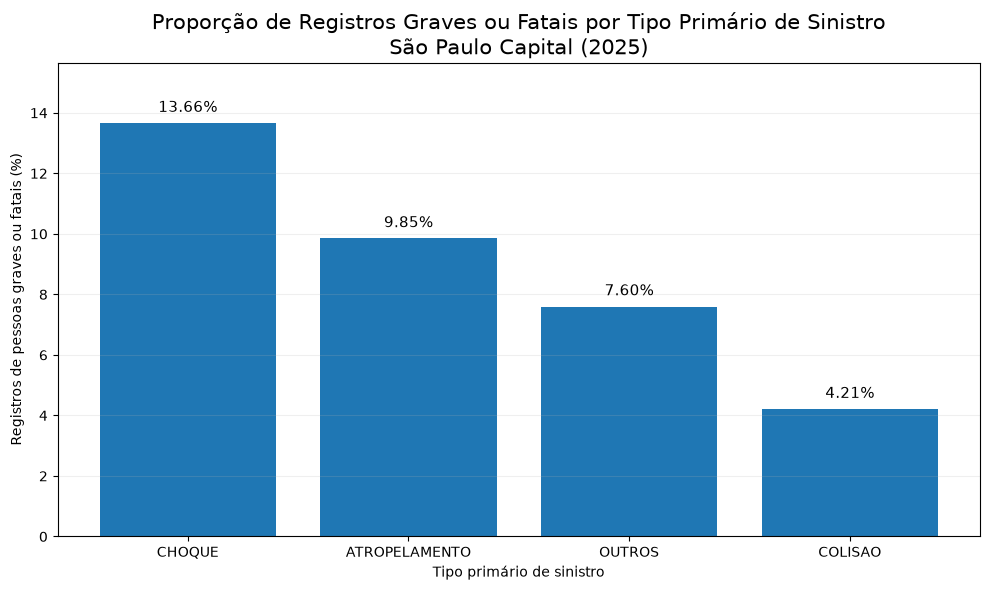

In [75]:
# GRÁFICO 21 - Proporção de registros graves ou fatais
# por tipo primário de sinistro
# São Paulo capital - 2025

dados_grafico21 = resumo_tipo_gravidade.drop(
    index="NAO DISPONIVEL",
    errors="ignore"
).copy()

dados_grafico21 = dados_grafico21.sort_values(
    "Grave_ou_Fatal_percentual",
    ascending=False
)

plt.figure(figsize=(10, 6))

barras = plt.bar(
    dados_grafico21.index,
    dados_grafico21["Grave_ou_Fatal_percentual"]
)

# Valores sobre as barras
for barra, valor in zip(
    barras,
    dados_grafico21["Grave_ou_Fatal_percentual"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.25,
        f"{valor:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title(
    "Proporção de Registros Graves ou Fatais por Tipo Primário de Sinistro\n"
    "São Paulo Capital (2025)",
    fontsize=15
)

plt.xlabel("Tipo primário de sinistro")
plt.ylabel("Registros de pessoas graves ou fatais (%)")

plt.ylim(
    0,
    dados_grafico21["Grave_ou_Fatal_percentual"].max() + 2
)

plt.grid(
    axis="y",
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "21_gravidade_tipo_sinistro_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()